Imports

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from pathlib import Path
from collections import Counter

Setting up the path

In [4]:
from pathlib import Path
import pandas as pd

# Find repository root
ROOT = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "src" / "download_meps.py").is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Could not find the repository root."
    )

print(f"Repository: {ROOT}")

Repository: C:\Users\chalv\statin-discontinuation


loading outputs

In [6]:
# Final analysis dataset: one row per person
baseline = pd.read_csv(
    ROOT / "data" / "processed" / "baseline_person_dataset.csv",
    dtype={"DUPERSID": "string"}
)

# Supporting datasets for additional EDA and data-quality checks
history = pd.read_csv(
    ROOT / "data" / "interim" / "person_round_history.csv",
    dtype={"DUPERSID": "string"}
)

statin_purchases = pd.read_csv(
    ROOT / "data" / "interim" / "statin_purchases.csv",
    dtype={"DUPERSID": "string"}
)

study_cohort = pd.read_csv(
    ROOT / "data" / "processed" / "study_cohort.csv",
    dtype={"DUPERSID": "string"}
)

join_audit = pd.read_csv(
    ROOT / "data" / "interim" / "join_audit.csv"
)

unmatched_keys = pd.read_csv(
    ROOT / "data" / "interim" / "unmatched_linkage_keys.csv"
)

cohort_flow = pd.read_csv(
    ROOT / "data" / "processed" / "cohort_flow.csv"
)

label_balance = pd.read_csv(
    ROOT / "data" / "processed" / "label_balance.csv"
)

# Organize datasets for inspection
datasets = {
    "Final baseline dataset": baseline,
    "Study cohort": study_cohort,
    "Person-round history": history,
    "Statin purchases": statin_purchases,
    "Join audit": join_audit,
    "Unmatched keys": unmatched_keys,
    "Cohort flow": cohort_flow,
    "Label balance": label_balance
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

# Verify one row per person
assert baseline["DUPERSID"].is_unique
assert baseline["DUPERSID"].notna().all()

print("\nOne row per person confirmed.")


Final baseline dataset: (1339, 79)
Study cohort: (1339, 2)
Person-round history: (41460, 41)
Statin purchases: (12395, 13)
Join audit: (2, 8)
Unmatched keys: (4977, 3)
Cohort flow: (8, 3)
Label balance: (2, 4)

One row per person confirmed.


1. Data Inventory and Quality Checks
Research Question: What data do we have, and how do the files connect?

This section examines the available MEPS datasets to establish an understanding of their structure, contents, and relationships. Initial exploration will include reviewing file dimensions, variable names, data types, identifiers, and supporting MEPS documentation. Data quality will be assessed by examining duplicate records, missing values, and record counts across files to ensure the datasets can be reliably combined. Particular attention will be given to identifying the relevant interview rounds, survey years, and statin medication identifiers needed for the analysis.

The goal is to establish a clear understanding of the available data, identify potential quality concerns, and validate the relationships between datasets before constructing the study cohort.

1.1 Dataset inventory

In [9]:
# Dataset inventory
inventory = []

for name, df in datasets.items():
    inventory.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Duplicate Rows": df.duplicated().sum(),
        "Memory (MB)": round(
            df.memory_usage(deep=True).sum() / 1024**2, 2
        )
    })

inventory_df = pd.DataFrame(inventory)

display(inventory_df)


,Dataset,Rows,Columns,Duplicate Rows,Memory (MB)
0,Final baseline dataset,1339,79,0,1.87
1,Study cohort,1339,2,0,0.09
2,Person-round history,41460,41,0,24.17
3,Statin purchases,12395,13,0,6.12
4,Join audit,2,8,0,0.00
5,Unmatched keys,4977,3,0,0.48
6,Cohort flow,8,3,0,0.00
7,Label balance,2,4,0,0.00


1.2 Variable inventory

In [11]:
variable_inventory = []

for name, df in datasets.items():
    for col in df.columns:
        variable_inventory.append({
            "Dataset": name,
            "Variable": col,
            "Data Type": str(df[col].dtype),
            "Missing Count": df[col].isna().sum(),
            "Missing %": round(df[col].isna().mean() * 100, 2),
            "Unique Values": df[col].nunique()
        })

variable_inventory_df = pd.DataFrame(variable_inventory)

display(variable_inventory_df)

baseline_missingness = (
    variable_inventory_df[
        variable_inventory_df["Dataset"] == "Final baseline dataset"
    ]
    .sort_values("Missing %", ascending=False)
)

display(baseline_missingness)

,Dataset,Variable,Data Type,Missing Count,Missing %,Unique Values
0,Final baseline dataset,DUPERSID,string,0,0.0,1339
1,Final baseline dataset,discontinued,int64,0,0.0,2
2,Final baseline dataset,ALL5RDS_round_1,int64,0,0.0,1
3,Final baseline dataset,ALL5RDS_round_2,int64,0,0.0,1
4,Final baseline dataset,DIED_round_1,int64,0,0.0,1
...,...,...,...,...,...,...
148,Cohort flow,excluded_at_step,int64,0,0.0,8
149,Label balance,label,int64,0,0.0,2
150,Label balance,outcome,object,0,0.0,2
151,Label balance,person_count,int64,0,0.0,2


,Dataset,Variable,Data Type,Missing Count,Missing %,Unique Values
62,Final baseline dataset,standardized_statins_round_1,object,374,27.93,8
63,Final baseline dataset,standardized_statins_round_2,object,216,16.13,8
64,Final baseline dataset,generic_drug_names_round_1,object,175,13.07,1036
66,Final baseline dataset,reported_drug_names_round_1,object,172,12.85,1055
74,Final baseline dataset,active_icd10_codes_round_1,object,134,10.01,908
...,...,...,...,...,...,...
25,Final baseline dataset,LONGWT_round_2,float64,0,0.00,1339
24,Final baseline dataset,LONGWT_round_1,float64,0,0.00,1339
23,Final baseline dataset,HWELLSPK_round_2,int64,0,0.00,5
22,Final baseline dataset,HWELLSPK_round_1,int64,0,0.00,5


1.3 Check identifiers

In [13]:

print("========== PERSON IDENTIFIER CHECKS ==========")

print(
    "Unique individuals in baseline:",
    baseline["DUPERSID"].nunique()
)

print(
    "Duplicate IDs in baseline:",
    baseline["DUPERSID"].duplicated().sum()
)

print(
    "Missing IDs in baseline:",
    baseline["DUPERSID"].isna().sum()
)

print(
    "Unique individuals in study cohort:",
    study_cohort["DUPERSID"].nunique()
)

print(
    "Unique individuals in history:",
    history["DUPERSID"].nunique()
)

print(
    "Unique individuals in statin purchases:",
    statin_purchases["DUPERSID"].nunique()
)

print(
    "Unique person-round combinations in history:",
    history[["DUPERSID", "ROUND"]].drop_duplicates().shape[0]
)

assert baseline["DUPERSID"].is_unique
assert baseline["DUPERSID"].notna().all()

print("\nBaseline person-level identifier validation passed.")


baseline_ids = set(baseline["DUPERSID"].dropna())
cohort_ids = set(study_cohort["DUPERSID"].dropna())

print("Baseline people:", len(baseline_ids))
print("Study cohort people:", len(cohort_ids))
print("People in baseline but not cohort:", len(baseline_ids - cohort_ids))
print("People in cohort but not baseline:", len(cohort_ids - baseline_ids))

========== PERSON IDENTIFIER CHECKS ==========
Unique individuals in baseline: 1339
Duplicate IDs in baseline: 0
Missing IDs in baseline: 0
Unique individuals in study cohort: 1339
Unique individuals in history: 8292
Unique individuals in statin purchases: 1985
Unique person-round combinations in history: 41460

Baseline person-level identifier validation passed.
Baseline people: 1339
Study cohort people: 1339
People in baseline but not cohort: 0
People in cohort but not baseline: 0


1.4 Review join validation

In [15]:
display(join_audit)
display(unmatched_keys.head())

,join,left_rows_before,right_rows,rows_after,matched_left_rows,unmatched_left_rows,unmatched_right_rows,left_rows_dropped
0,longitudinal + prescriptions,41460,22170,41460,19992,21468,2178,0
1,longitudinal + prescriptions + conditions,41460,26144,41460,23345,18115,2799,0


,join,DUPERSID,ROUND
0,longitudinal + prescriptions,2790017102,1
1,longitudinal + prescriptions,2790017102,2
2,longitudinal + prescriptions,2790017103,1
3,longitudinal + prescriptions,2790017103,2
4,longitudinal + prescriptions,2790022101,1


In [16]:
print("========== PERSON-ROUND HISTORY ==========")
print(history.columns.tolist())

print("\n========== STATIN PURCHASES ==========")
print(statin_purchases.columns.tolist())

print("\n========== COHORT FLOW ==========")
display(cohort_flow)

print("\n========== LABEL BALANCE ==========")
display(label_balance)

========== PERSON-ROUND HISTORY ==========
['DUPERSID', 'PANEL', 'ALL5RDS', 'DIED', 'INST', 'MILITARY', 'LEFTUS', 'SEX', 'RACETHX', 'HISPANX', 'EDUCYR', 'HIDEG', 'HWELLSPK', 'LONGWT', 'ROUND', 'AGE', 'RTHLTH', 'MNHLTH', 'INS', 'MCARE', 'MCAID', 'PRIVAT', 'PMEDIN', 'ELGRND', 'INSCOP', 'BEGRFM', 'BEGRFY', 'ENDRFM', 'ENDRFY', 'MCRPD', 'rx_purchase_count', 'distinct_drug_count', 'statin_purchase_count', 'standardized_statins', 'generic_drug_names', 'reported_drug_names', 'statin_rx_cost', 'active_condition_count', 'new_condition_count', 'active_icd10_codes', 'active_ccsr_codes']

========== STATIN PURCHASES ==========
['DUPERSID', 'ROUND', 'RXRECIDX', 'DRUGIDX', 'RXSF', 'RXSF_SOURCE', 'standardized_statin', 'mapping_source', 'source_files', 'RXDRGNAM', 'RXNAME', 'TC1S1_1', 'TC2S1_1']

========== COHORT FLOW ==========


,step,eligible_n,excluded_at_step
0,Panel 27 longitudinal records,8292,0
1,Age at round 1 is at least 18,6571,1721
2,Not reported as deceased,6423,148
3,Not reported as institutionalized,6395,28
4,Not reported as active-duty military,6378,17
5,Not reported as moved out of the country,6355,23
6,Observed through all five rounds,6299,56
7,At least one statin purchase in rounds 1-2,1339,4960



========== LABEL BALANCE ==========


,label,outcome,person_count,proportion
0,0,continued,1232,0.92009
1,1,no observed statin purchase in rounds 3-5,107,0.07991


1.5 Observations by interview round

In [18]:
round_summary = (
    history.groupby("ROUND")
    .agg(
        Unique_Individuals=("DUPERSID", "nunique"),
        Total_Records=("DUPERSID", "size"),
        Statin_Purchases=("statin_purchase_count", "sum"),
        Individuals_With_Statin=(
            "statin_purchase_count",
            lambda x: (x > 0).sum()
        ),
        Total_Statin_OOP_Cost=("statin_rx_cost", "sum")
    )
    .reset_index()
)

display(round_summary)


,ROUND,Unique_Individuals,Total_Records,Statin_Purchases,Individuals_With_Statin,Total_Statin_OOP_Cost
0,1,8292,8292,1682,1006,10299.01
1,2,8292,8292,2561,1163,14475.23
2,3,8292,8292,2217,1212,11176.36
3,4,8292,8292,2893,1271,14437.72
4,5,8292,8292,2142,1149,10022.44


1.6 Validate prescription identifiers

In [20]:
print("========== PRESCRIPTION IDENTIFIER CHECKS ==========")

print(
    "Unique prescription record IDs:",
    statin_purchases["RXRECIDX"].nunique()
)

print(
    "Duplicate prescription record IDs:",
    statin_purchases["RXRECIDX"].duplicated().sum()
)

print(
    "Unique drug IDs:",
    statin_purchases["DRUGIDX"].nunique()
)

print(
    "Total statin purchase records:",
    len(statin_purchases)
)

print(
    "Unique individuals with statin purchases:",
    statin_purchases["DUPERSID"].nunique()
)

print("\n========== PURCHASES BY PERSON AND ROUND ==========")

purchase_summary = (
    statin_purchases.groupby(["DUPERSID", "ROUND"])
    .size()
    .reset_index(name="Purchase_Records")
)

display(purchase_summary.head(10))

print(
    "Person-round purchase combinations:",
    len(purchase_summary)
)


========== PRESCRIPTION IDENTIFIER CHECKS ==========
Unique prescription record IDs: 12395
Duplicate prescription record IDs: 0
Unique drug IDs: 2292
Total statin purchase records: 12395
Unique individuals with statin purchases: 1985

========== PURCHASES BY PERSON AND ROUND ==========


,DUPERSID,ROUND,Purchase_Records
0,2790006101,2,2
1,2790006101,3,1
2,2790006101,4,2
3,2790006101,5,2
4,2790011101,1,1
5,2790011101,2,10
6,2790011101,3,2
7,2790011101,5,1
8,2790011102,2,11
9,2790011102,4,1


Person-round purchase combinations: 6285


1.7 Dataset Validation

In [22]:
print("========== FINAL BASELINE DATASET ==========")

print("Dataset dimensions:", baseline.shape)
print("Unique individuals:", baseline["DUPERSID"].nunique())
print("Duplicate individuals:", baseline["DUPERSID"].duplicated().sum())
print("Missing person IDs:", baseline["DUPERSID"].isna().sum())

print(
    "Baseline statin OOP cost column:",
    "statin_rx_cost_baseline_total" in baseline.columns
)

assert baseline.shape[0] == baseline["DUPERSID"].nunique()
assert baseline["DUPERSID"].notna().all()
assert baseline["DUPERSID"].is_unique

print("\nFinal baseline dataset validation passed.")


========== FINAL BASELINE DATASET ==========
Dataset dimensions: (1339, 79)
Unique individuals: 1339
Duplicate individuals: 0
Missing person IDs: 0
Baseline statin OOP cost column: True

Final baseline dataset validation passed.


Data Inventory and Quality Checks Summary

Research Question: What data do we have, and how do the files connect?

The study contains eight interconnected datasets that provide the person-level, longitudinal, prescription, and cohort information needed for the analysis. These datasets are primarily linked through individual identifiers (DUPERSID) and, where applicable, interview rounds (ROUND). Validation confirmed that the final baseline dataset and study cohort contain the same 1,339 individuals, with one unique record per person. 

Key Findings:

Dataset structure: The final baseline dataset contains 1,339 individuals and 79 variables, while the longitudinal history contains 41,460 observations across 8,292 individuals and five interview rounds.

Data integrity: No exact duplicate rows were identified across the eight datasets. Person-level identifiers in the baseline dataset and prescription record identifiers were unique.

Prescription records: The statin purchase dataset contains 12,395 prescription records representing 1,985 individuals and 2,292 unique drug identifiers. Purchasing activity varies across interview rounds.

Join validation: Prescription and condition joins preserved all 41,460 longitudinal records without dropping rows. However, unmatched records were identified on both sides of the joins and should be considered when interpreting linked variables.

Cohort and outcome: The eligibility criteria produced a final cohort of 1,339 individuals. Of these, 1,232 (92.01%) continued to have observed statin purchases, while 107 (7.99%) had no observed statin purchases in rounds 3–5.

Missing data: Missingness was concentrated primarily in medication and condition related variables. Standardized statin information was missing for 27.93% of individuals in round 1 and 16.13% in round 2.




2. Cohort Construction and Outcome Definition
Research Question: Can we reliably define our study population and potential discontinuation?

This section focuses on establishing the study population and defining the outcome variable for subsequent analysis. The cohort will consist of adults with recorded statin purchases during rounds 1–2 who remain observable through round 5. Prescription purchasing histories will be summarized at the individual and interview-round levels to establish baseline statin use and evaluate purchasing behavior during rounds 3–5.

Potential statin discontinuation will be defined using purchasing activity during the later interview rounds. The outcome definition will be examined for ambiguous purchasing histories, changes in statin medications, and other patterns that could affect classification. This process is intended to ensure that the study population and outcome are consistently and defensibly defined.e

2.1: Cohort attrition

In [26]:
display(cohort_flow)

,step,eligible_n,excluded_at_step
0,Panel 27 longitudinal records,8292,0
1,Age at round 1 is at least 18,6571,1721
2,Not reported as deceased,6423,148
3,Not reported as institutionalized,6395,28
4,Not reported as active-duty military,6378,17
5,Not reported as moved out of the country,6355,23
6,Observed through all five rounds,6299,56
7,At least one statin purchase in rounds 1-2,1339,4960


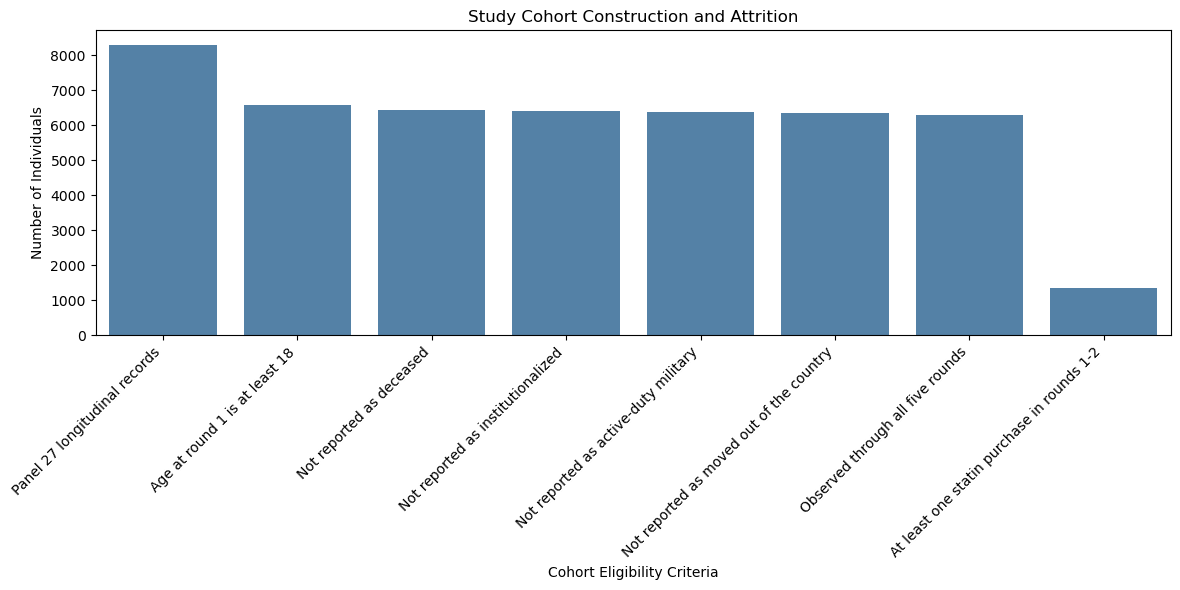

In [27]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=cohort_flow,
    x="step",
    y="eligible_n",
    color="steelblue"
)

plt.title("Study Cohort Construction and Attrition")
plt.xlabel("Cohort Eligibility Criteria")
plt.ylabel("Number of Individuals")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [28]:
# Formatted cohort flow table
cohort_table = cohort_flow.copy()

cohort_table["Percent of Initial Cohort"] = (
    cohort_table["eligible_n"] /
    cohort_table["eligible_n"].iloc[0] * 100
).round(2)

cohort_table["Percent Excluded at Step"] = (
    cohort_table["excluded_at_step"] /
    cohort_table["eligible_n"].shift(1) * 100
).fillna(0).round(2)

cohort_table = cohort_table.rename(columns={
    "step": "Eligibility Criterion",
    "eligible_n": "Remaining Individuals",
    "excluded_at_step": "Individuals Excluded"
})

display(cohort_table)

,Eligibility Criterion,Remaining Individuals,Individuals Excluded,Percent of Initial Cohort,Percent Excluded at Step
0,Panel 27 longitudinal records,8292,0,100.00,0.00
1,Age at round 1 is at least 18,6571,1721,79.25,20.75
2,Not reported as deceased,6423,148,77.46,2.25
3,Not reported as institutionalized,6395,28,77.12,0.44
4,Not reported as active-duty military,6378,17,76.92,0.27
5,Not reported as moved out of the country,6355,23,76.64,0.36
6,Observed through all five rounds,6299,56,75.96,0.88
7,At least one statin purchase in rounds 1-2,1339,4960,16.15,78.74


2.2 Purchase history

In [30]:
print("Baseline dataset dimensions:", baseline.shape)

print("Unique individuals:", baseline["DUPERSID"].nunique())

display(baseline.head())

Baseline dataset dimensions: (1339, 79)
Unique individuals: 1339


,DUPERSID,discontinued,ALL5RDS_round_1,ALL5RDS_round_2,DIED_round_1,DIED_round_2,INST_round_1,INST_round_2,MILITARY_round_1,MILITARY_round_2,...,statin_rx_cost_round_2,active_condition_count_round_1,active_condition_count_round_2,new_condition_count_round_1,new_condition_count_round_2,active_icd10_codes_round_1,active_icd10_codes_round_2,active_ccsr_codes_round_1,active_ccsr_codes_round_2,statin_rx_cost_baseline_total
0,2790006101,0,1,1,0,0,0,0,0,0,...,18.00,2,4,2,0,C50; E03,C50; E03; E11; E78,END001; NEO030,END001; END002; END005; END010; NEO030,18.00
1,2790011101,0,1,1,0,0,0,0,0,0,...,100.00,1,1,1,0,E78,E78,END010,END010,110.00
2,2790011102,0,1,1,0,0,0,0,0,0,...,72.46,3,7,3,4,I10; M79; S82,E78; I10; M79; S82,CIR007; INJ042; MUS025,CIR007; END010; INJ000; INJ042; MUS025; RSP000...,72.46
3,2790021101,0,1,1,0,0,0,0,0,0,...,0.00,1,3,1,1,E11,E11; E78; M10,END002; END005,END002; END005; END010; MUS033,0.00
4,2790049101,0,1,1,0,0,0,0,0,0,...,32.60,3,5,3,2,E78; H40; Z96,E78; H40; M25; M48; Z96,END010; EYE003; FAC009,END010; EYE003; FAC009; MUS010; MUS011,47.21


2.3 Outcome definition

In [32]:
outcome_summary = (
    baseline["discontinued"]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Continued",
        1: "No observed statin purchase"
    })
    .to_frame("Individuals")
)

outcome_summary["Percentage"] = (
    outcome_summary["Individuals"] /
    len(baseline) * 100
).round(2)

display(outcome_summary)

,Individuals,Percentage
discontinued,,
Continued,1232,92.01
No observed statin purchase,107,7.99


2.4 Baseline Statin Cost Analysis

In [34]:
baseline_purchase_summary = baseline[
    [
        "statin_rx_cost_baseline_total",
        "discontinued"
    ]
].groupby("discontinued").agg(
    Individuals=("statin_rx_cost_baseline_total", "count"),
    Mean_Baseline_Cost=("statin_rx_cost_baseline_total", "mean"),
    Median_Baseline_Cost=("statin_rx_cost_baseline_total", "median"),
    Total_Baseline_Cost=("statin_rx_cost_baseline_total", "sum")
).round(2)

display(baseline_purchase_summary)

,Individuals,Mean_Baseline_Cost,Median_Baseline_Cost,Total_Baseline_Cost
discontinued,,,,
0,1232,17.81,0.00,21943.02
1,107,21.59,4.39,2309.79


2.5 Baseline Characteristics by Outcome

In [36]:
baseline_comparison = (
    baseline.groupby("discontinued")
    .agg(
        Individuals=("DUPERSID", "nunique"),
        Mean_Age=("AGE_round_1", "mean"),
        Mean_Statin_Cost=("statin_rx_cost_baseline_total", "mean")
    )
    .round(2)
    .reset_index()
)

display(baseline_comparison)

,discontinued,Individuals,Mean_Age,Mean_Statin_Cost
0,0,1232,67.42,17.81
1,1,107,62.97,21.59


2.6 Baseline Statin Characteristics

In [38]:
print("Baseline statin characteristics:")

display(
    baseline[
        [
            "standardized_statins_round_1",
            "standardized_statins_round_2"
        ]
    ].describe(include="all")
)

Baseline statin characteristics:


,standardized_statins_round_1,standardized_statins_round_2
count,965,1123
unique,8,8
top,ATORVASTATIN,ATORVASTATIN
freq,544,641


Cohort Construction and Outcome Definition  Summary
Research Question: Can we reliably define our study population and potential discontinuation?

The available longitudinal and prescription data support a consistent definition of the study population and a measurable potential discontinuation outcome. Applying the eligibility criteria identified 1,339 adults with at least one recorded statin purchase during rounds 1–2 who remained observable through all five interview rounds. The outcome was defined as having no observed statin purchases during rounds 3–5. 

Key Findings:

Cohort construction: The initial 8,292 Panel 27 participants were reduced to 6,299 after applying demographic, exclusion, and longitudinal observation criteria. Requiring at least one statin purchase during rounds 1–2 further reduced the analytical cohort to 1,339 individuals, representing 16.15% of the initial population.

Outcome distribution: Of the 1,339 individuals, 1,232 (92.01%) had at least one observed statin purchase during rounds 3–5, while 107 (7.99%) had no observed follow-up purchase. This indicates substantial class imbalance, with the potential discontinuation group representing a relatively small proportion of the cohort.

Baseline statin costs: Individuals without observed follow-up purchases had a higher mean baseline out-of-pocket statin cost (21.59 USD) than individuals who continued purchasing (17.81 USD). Their median costs were also higher (4.39 USD compared with 0.00 USD), suggesting differences in baseline purchasing costs between outcome groups.

Baseline characteristics: Individuals without observed follow up purchases were younger on average (62.97 years) than those with continued purchases (67.42 years). These differences provide candidate predictors for further investigation.

Medication characteristics: Atorvastatin was the most frequently recorded standardized statin in both baseline rounds. Standardized medication information was available for 965 individuals in round 1 and 1,123 in round 2, indicating incomplete medication classification that should be considered during feature selection andreprocessing.



3. Univariate Analysis
Research Question: What do our variables look like individually?

This section explores the distribution and characteristics of individual variables within the study cohort. Numerical variables, such as age, healthcare costs, income, and medication counts, will be examined alongside categorical variables, including insurance status, demographic characteristics, and access to care.

The analysis will assess missingness, outliers, skewness, and the frequency of rare categories to identify potential issues that may influence subsequent modeling. Histograms, box plots, bar charts, and missingness visualizations will be used to better understand the distributions and overall quality of the available features..

3.1 preparing the baseline dataset

In [42]:
# Load the consolidated baseline dataset
baseline_data = pd.read_csv(
    ROOT / "data" / "processed" / "baseline_person_dataset.csv",
    dtype={"DUPERSID": "string"}
)

print("Baseline dataset dimensions:", baseline_data.shape)
print("Unique individuals:", baseline_data["DUPERSID"].nunique())
print("Duplicate individuals:", baseline_data["DUPERSID"].duplicated().sum())
print("Missing person IDs:", baseline_data["DUPERSID"].isna().sum())

assert baseline_data["DUPERSID"].is_unique
assert baseline_data["DUPERSID"].notna().all()

print("\nOutcome distribution:")
display(baseline_data["discontinued"].value_counts().sort_index())

display(baseline_data.head())

Baseline dataset dimensions: (1339, 79)
Unique individuals: 1339
Duplicate individuals: 0
Missing person IDs: 0

Outcome distribution:


discontinued
0    1232
1     107
Name: count, dtype: int64

,DUPERSID,discontinued,ALL5RDS_round_1,ALL5RDS_round_2,DIED_round_1,DIED_round_2,INST_round_1,INST_round_2,MILITARY_round_1,MILITARY_round_2,...,statin_rx_cost_round_2,active_condition_count_round_1,active_condition_count_round_2,new_condition_count_round_1,new_condition_count_round_2,active_icd10_codes_round_1,active_icd10_codes_round_2,active_ccsr_codes_round_1,active_ccsr_codes_round_2,statin_rx_cost_baseline_total
0,2790006101,0,1,1,0,0,0,0,0,0,...,18.00,2,4,2,0,C50; E03,C50; E03; E11; E78,END001; NEO030,END001; END002; END005; END010; NEO030,18.00
1,2790011101,0,1,1,0,0,0,0,0,0,...,100.00,1,1,1,0,E78,E78,END010,END010,110.00
2,2790011102,0,1,1,0,0,0,0,0,0,...,72.46,3,7,3,4,I10; M79; S82,E78; I10; M79; S82,CIR007; INJ042; MUS025,CIR007; END010; INJ000; INJ042; MUS025; RSP000...,72.46
3,2790021101,0,1,1,0,0,0,0,0,0,...,0.00,1,3,1,1,E11,E11; E78; M10,END002; END005,END002; END005; END010; MUS033,0.00
4,2790049101,0,1,1,0,0,0,0,0,0,...,32.60,3,5,3,2,E78; H40; Z96,E78; H40; M25; M48; Z96,END010; EYE003; FAC009,END010; EYE003; FAC009; MUS010; MUS011,47.21


3.2 Classify variables

In [44]:
numerical_vars = [
    # Demographics
    "AGE_round_1",
    "EDUCYR_round_1",

    # Financial characteristics
    "statin_rx_cost_round_1",
    "statin_rx_cost_round_2",
    "statin_rx_cost_baseline_total",

    # Prescription characteristics
    "rx_purchase_count_round_1",
    "rx_purchase_count_round_2",
    "distinct_drug_count_round_1",
    "distinct_drug_count_round_2",
    "statin_purchase_count_round_1",
    "statin_purchase_count_round_2",

    # Health characteristics
    "active_condition_count_round_1",
    "active_condition_count_round_2",
    "new_condition_count_round_1",
    "new_condition_count_round_2",

    # Survey weights
    "LONGWT_round_1",
    "LONGWT_round_2"
]

categorical_vars = [
    # Demographics
    "SEX_round_1",
    "RACETHX_round_1",
    "HISPANX_round_1",
    "HIDEG_round_1",

    # Health
    "RTHLTH_round_1",
    "MNHLTH_round_1",

    # Healthcare access
    "INS_round_1",
    "MCARE_round_1",
    "MCAID_round_1",
    "PRIVAT_round_1",
    "PMEDIN_round_1",
    "INSCOP_round_1",
    "ELGRND_round_1",

    # Outcome
    "discontinued"
]

numerical_vars = [
    col for col in numerical_vars
    if col in baseline_data.columns
]

categorical_vars = [
    col for col in categorical_vars
    if col in baseline_data.columns
]

print("Numerical variables:", numerical_vars)
print("\nCategorical variables:", categorical_vars)

Numerical variables: ['AGE_round_1', 'EDUCYR_round_1', 'statin_rx_cost_round_1', 'statin_rx_cost_round_2', 'statin_rx_cost_baseline_total', 'rx_purchase_count_round_1', 'rx_purchase_count_round_2', 'distinct_drug_count_round_1', 'distinct_drug_count_round_2', 'statin_purchase_count_round_1', 'statin_purchase_count_round_2', 'active_condition_count_round_1', 'active_condition_count_round_2', 'new_condition_count_round_1', 'new_condition_count_round_2', 'LONGWT_round_1', 'LONGWT_round_2']

Categorical variables: ['SEX_round_1', 'RACETHX_round_1', 'HISPANX_round_1', 'HIDEG_round_1', 'RTHLTH_round_1', 'MNHLTH_round_1', 'INS_round_1', 'MCARE_round_1', 'MCAID_round_1', 'PRIVAT_round_1', 'PMEDIN_round_1', 'INSCOP_round_1', 'ELGRND_round_1', 'discontinued']


3.3 Missingness analysis

In [46]:
eda_vars = numerical_vars + categorical_vars

missing_summary = pd.DataFrame({
    "Variable": eda_vars,
    "Missing Count": [
        baseline_data[col].isna().sum()
        for col in eda_vars
    ],
    "Missing Percentage": [
        baseline_data[col].isna().mean() * 100
        for col in eda_vars
    ]
})

missing_summary = missing_summary.sort_values(
    "Missing Percentage",
    ascending=False
)

display(missing_summary.round(2))

,Variable,Missing Count,Missing Percentage
0,AGE_round_1,0,0.0
16,LONGWT_round_2,0,0.0
29,ELGRND_round_1,0,0.0
28,INSCOP_round_1,0,0.0
27,PMEDIN_round_1,0,0.0
26,PRIVAT_round_1,0,0.0
25,MCAID_round_1,0,0.0
24,MCARE_round_1,0,0.0
23,INS_round_1,0,0.0
22,MNHLTH_round_1,0,0.0


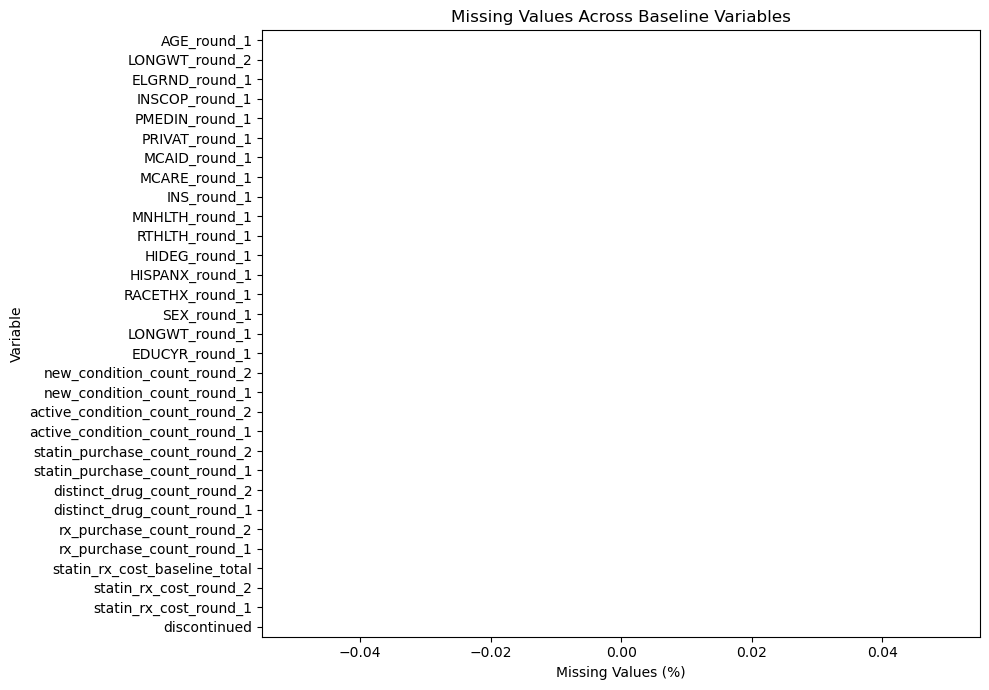

In [47]:
plt.figure(figsize=(10, 7))

missing_plot = (
    baseline_data[eda_vars]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

sns.barplot(
    x=missing_plot.values,
    y=missing_plot.index,
    color="steelblue"
)

plt.title("Missing Values Across Baseline Variables")
plt.xlabel("Missing Values (%)")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

3.4 Numerical descriptive statistics

In [49]:
numerical_summary = baseline_data[numerical_vars].describe().T

numerical_summary["missing"] = (
    baseline_data[numerical_vars].isna().sum()
)

numerical_summary["skewness"] = (
    baseline_data[numerical_vars].skew()
)

numerical_summary["zero_count"] = (
    baseline_data[numerical_vars].eq(0).sum()
)

display(numerical_summary.round(2))

,count,mean,std,min,25%,50%,75%,max,missing,skewness,zero_count
AGE_round_1,1339.0,67.06,11.09,25.00,60.50,68.00,75.00,85.00,0,-0.59,0
EDUCYR_round_1,1339.0,12.99,3.49,-8.00,12.00,13.00,16.00,17.00,0,-1.75,4
statin_rx_cost_round_1,1339.0,7.50,46.31,0.00,0.00,0.00,4.64,1524.80,0,27.24,895
statin_rx_cost_round_2,1339.0,10.62,54.61,0.00,0.00,0.00,9.08,1829.76,0,28.05,809
statin_rx_cost_baseline_total,1339.0,18.11,97.54,0.00,0.00,1.00,17.66,3354.56,0,30.22,664
rx_purchase_count_round_1,1339.0,7.62,9.99,0.00,2.00,5.00,9.00,101.00,0,3.46,172
rx_purchase_count_round_2,1339.0,12.06,13.90,0.00,4.00,8.00,15.00,135.00,0,3.08,58
distinct_drug_count_round_1,1339.0,4.44,3.81,0.00,2.00,4.00,6.00,24.00,0,1.41,172
distinct_drug_count_round_2,1339.0,5.28,3.77,0.00,3.00,5.00,7.00,25.00,0,1.21,58
statin_purchase_count_round_1,1339.0,1.20,1.28,0.00,0.00,1.00,1.00,7.00,0,1.89,373


3.5 Numerical Distribution Plots

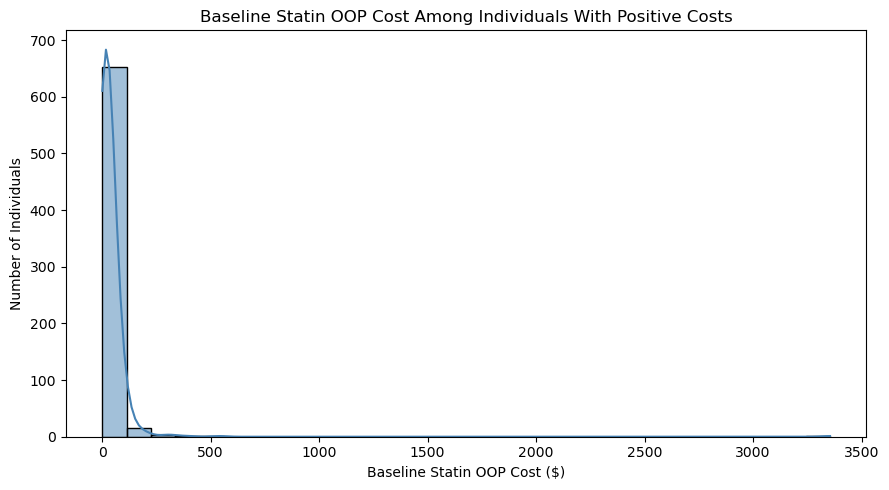

In [51]:
positive_costs = baseline_data.loc[
    baseline_data["statin_rx_cost_baseline_total"] > 0,
    "statin_rx_cost_baseline_total"
]

plt.figure(figsize=(9, 5))

sns.histplot(
    positive_costs,
    bins=30,
    kde=True,
    color="steelblue"
)

plt.title("Baseline Statin OOP Cost Among Individuals With Positive Costs")
plt.xlabel("Baseline Statin OOP Cost ($)")
plt.ylabel("Number of Individuals")

plt.tight_layout()
plt.show()

3.6 Categorical variable distributions

In [53]:
for col in categorical_vars:

    print(f"\n========== {col} ==========")

    summary = (
        baseline_data[col]
        .value_counts(dropna=False)
        .rename_axis("Category")
        .reset_index(name="Count")
    )

    summary["Percentage"] = (
        summary["Count"] / len(baseline_data) * 100
    ).round(2)

    display(summary)


========== SEX_round_1 ==========


,Category,Count,Percentage
0,2,682,50.93
1,1,657,49.07



========== RACETHX_round_1 ==========


,Category,Count,Percentage
0,2,896,66.92
1,1,193,14.41
2,3,170,12.70
3,4,50,3.73
4,5,30,2.24



========== HISPANX_round_1 ==========


,Category,Count,Percentage
0,2,1146,85.59
1,1,193,14.41


... (18 outputs left out)


========== ELGRND_round_1 ==========


,Category,Count,Percentage
0,1,1339,100.0



========== discontinued ==========


,Category,Count,Percentage
0,0,1232,92.01
1,1,107,7.99


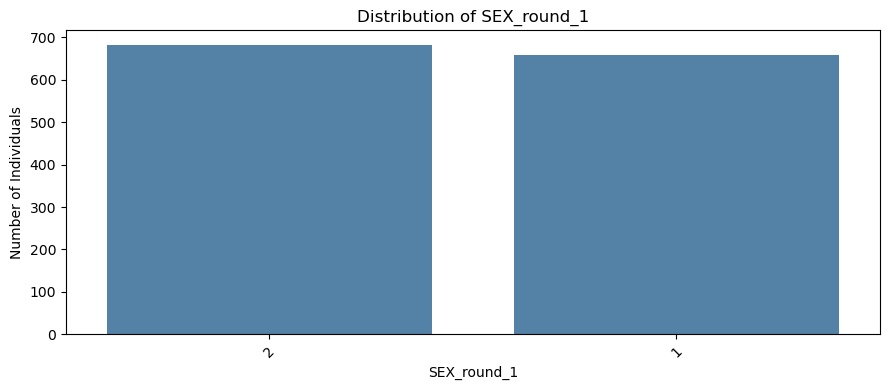

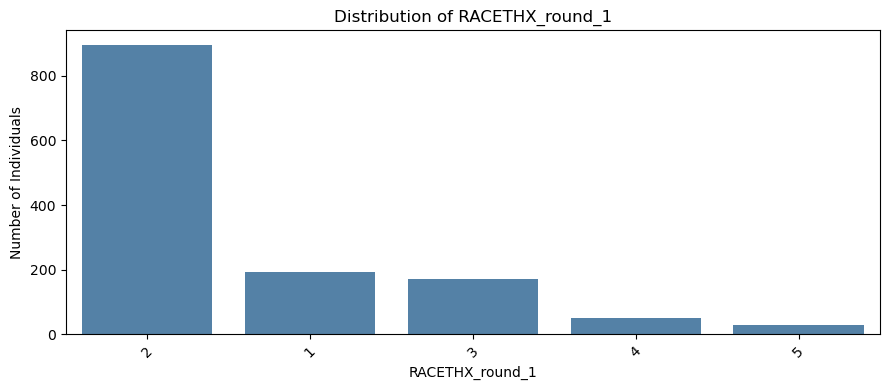

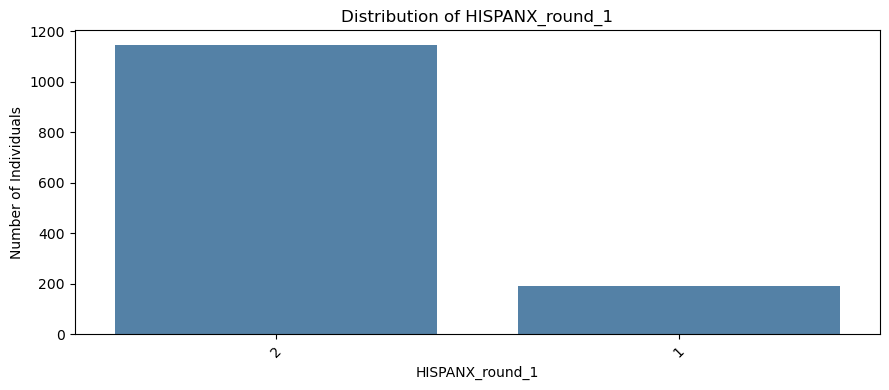

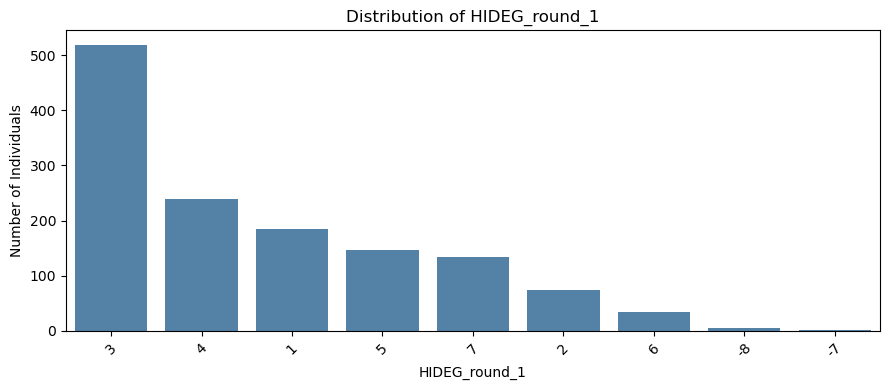

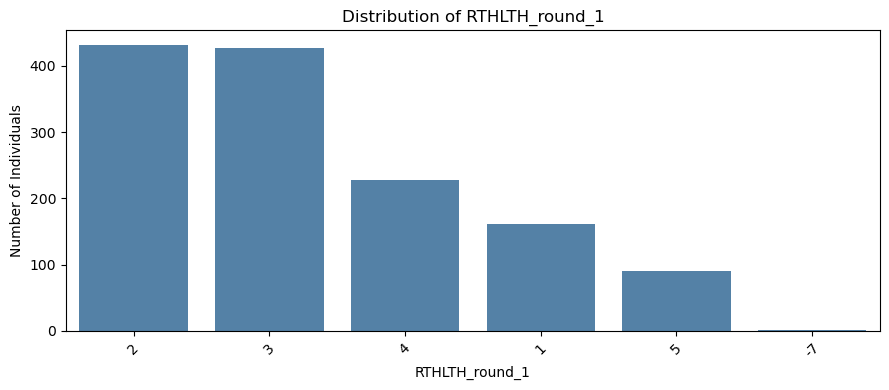

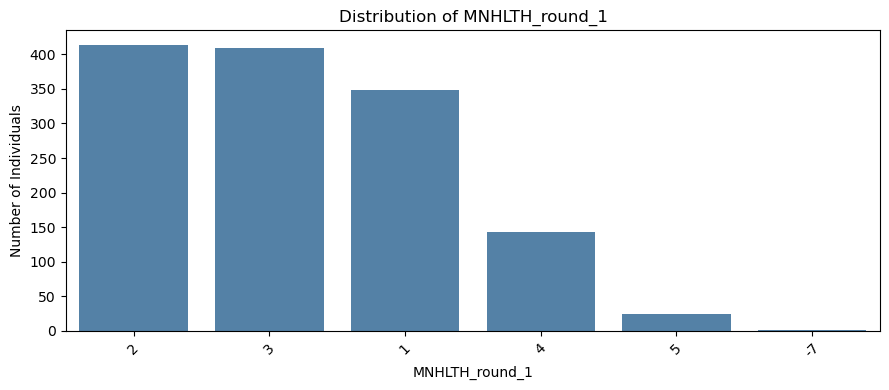

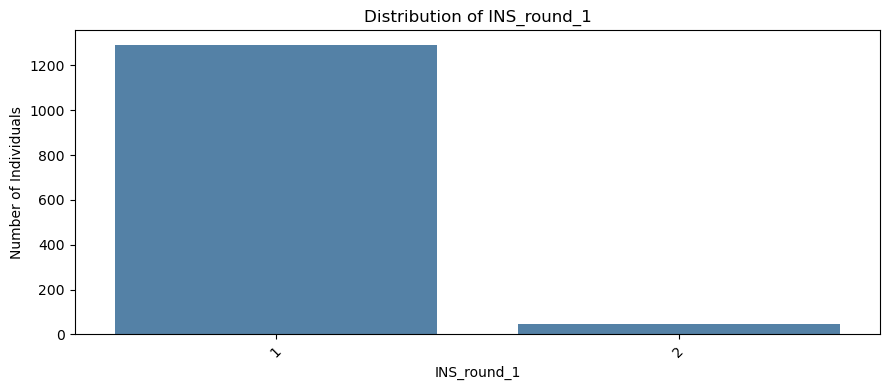

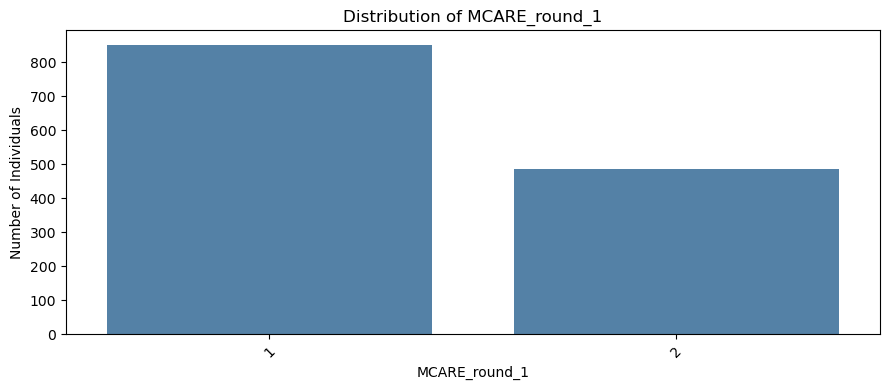

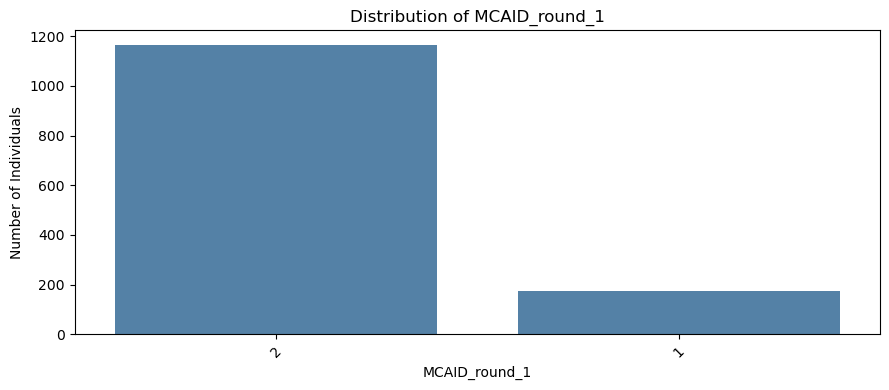

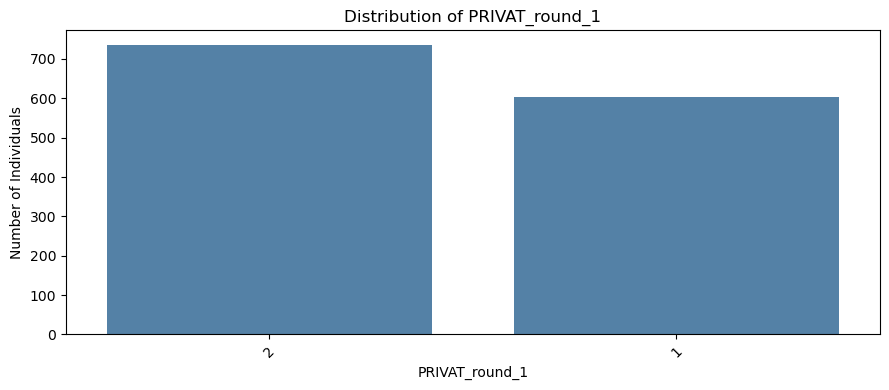

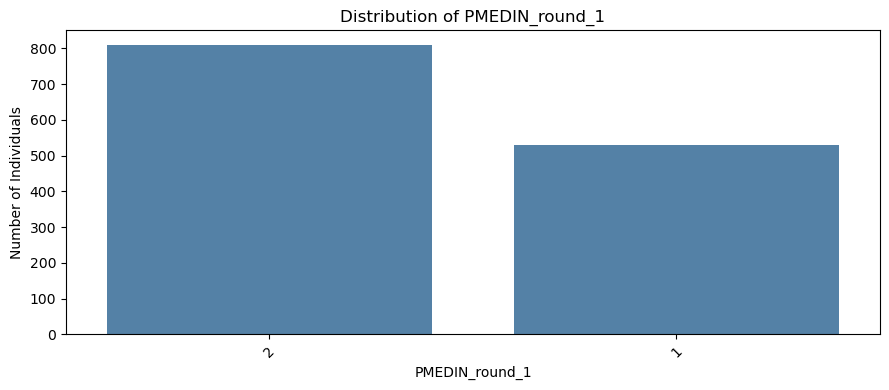

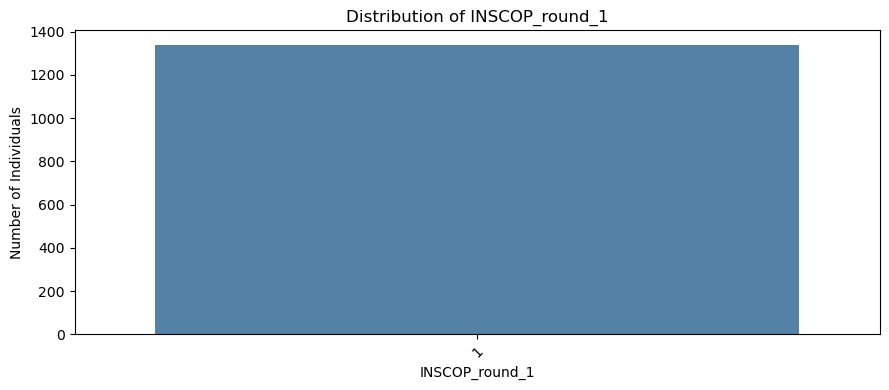

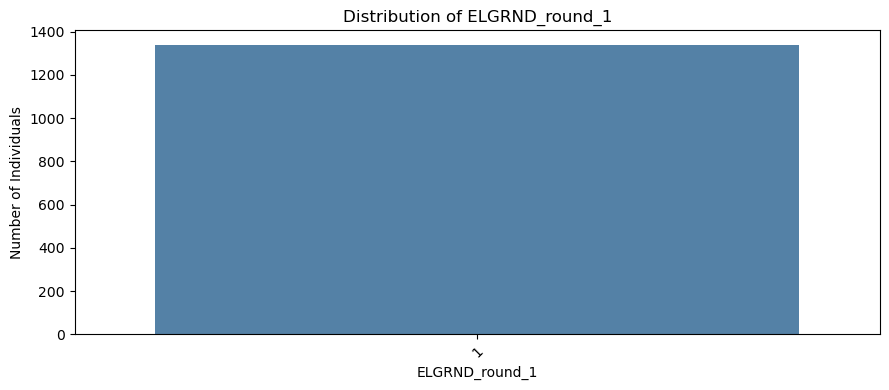

In [54]:
plot_vars = [
    col for col in categorical_vars
    if col != "discontinued"
]

for col in plot_vars:

    plt.figure(figsize=(9, 4))

    order = baseline_data[col].value_counts().index

    sns.countplot(
        data=baseline_data,
        x=col,
        order=order,
        color="steelblue"
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Individuals")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

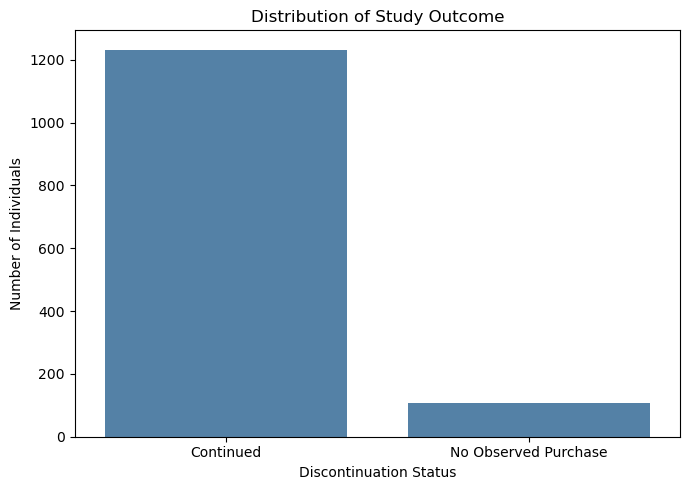

In [55]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=baseline_data,
    x="discontinued",
    color="steelblue"
)

plt.title("Distribution of Study Outcome")
plt.xlabel("Discontinuation Status")
plt.ylabel("Number of Individuals")

plt.xticks(
    [0, 1],
    ["Continued", "No Observed Purchase"]
)

plt.tight_layout()
plt.show()

Univariate Analysis Summary

Research Question: What do our variables look like individually?

The study cohort consists primarily of older adults with substantial variation in prescription utilization, healthcare characteristics, and financial measures. The selected baseline variables are largely complete, although some categorical variables contain special MEPS survey codes that require appropriate treatment. Overall, the univariate analysis provides a clearer understanding of the population's demographic composition, financial characteristics, health status, and healthcare access before examining relationships between predictors and the study outcome.

Key Findings:

Demographic characteristics: Participants had a mean age of 67.06 years (SD = 11.09), indicating an older adult study population. The cohort was relatively balanced across the two recorded sex categories (50.93% and 49.07%). The largest race/ethnicity category represented 66.92% of participants, while 85.59% were classified in the non-Hispanic category. Education levels varied, with the largest category representing 38.76% of the cohort.

Financial and prescription characteristics: Prescription utilization increased between rounds 1 and 2. Mean prescription purchase counts increased from 7.62 to 12.06, while mean distinct medication counts increased from 4.44 to 5.28. Mean statin purchase counts increased from 1.20 to 1.85. Combined baseline statin out of pocket costs averaged 18.11 USD, with a median of 1.00 USD. Notably, 664 individuals (49.59%) had zero recorded baseline statin costs. Financial variables exhibited substantial right skewness, indicating that a relatively small number of individuals had considerably higher recorded costs.

Health characteristics: Participants had an average of 3.89 active conditions in round 1 and 4.86 in round 2. Newly recorded conditions averaged 3.89 in round 1 and 1.69 in round 2. Self-reported physical and mental health categories also varied across the cohort.

Healthcare access and insurance: Approximately 96.49% of participants had recorded insurance coverage. Medicare coverage was recorded for 63.63%, Medicaid for 12.99%, and private insurance for 45.03%. Prescription medicine coverage was recorded for 39.51%. The INSCOP_round_1 and ELGRND_round_1 variables had no variation, with all participants assigned to the same category, limiting their potential usefulness as predictive features.

Missing data and data quality: All selected numerical and categorical variables had zero missing values. However, certain categorical variables contained special MEPS codes, including -7 and -8. Medication-related variables outside the selected feature set also contained missing values, particularly standardized statin names.

Outcome distribution: The cohort remained substantially imbalanced, with 1,232 individuals (92.01%) classified as continuing statin purchases and 107 (7.99%) having no observed statin purchases during rounds 3–5.



4. Feature Comparisons and Purchase Patterns
Research Question: How do patients with and without recorded discontinuation differ, and do early purchasing patterns provide useful signals?

This section investigates differences between individuals with and without recorded statin discontinuation to identify potentially meaningful patterns in the study population. Baseline characteristics, including healthcare costs, demographics, insurance coverage, and access to care, will be compared across outcome groups.

In addition to examining baseline characteristics, this analysis will explore early statin purchasing behavior during rounds 1–2. Factors such as purchase frequency, out-of-pocket costs, medication switching, and purchasing consistency will be evaluated to determine whether early purchasing patterns may provide useful information about later discontinuation.

Grouped histograms, box plots, violin plots, bar charts, and summary tables will be used to identify differences between outcome groups and highlight potentially useful predictive features.

4.1 Prepare the analysis dataset

In [59]:
analysis_data = baseline.copy()

print("Analysis dataset:", analysis_data.shape)
print("Unique individuals:", analysis_data["DUPERSID"].nunique())

print("\nOutcome distribution:")
display(
    analysis_data["discontinued"].value_counts()
)

Analysis dataset: (1339, 79)
Unique individuals: 1339

Outcome distribution:


discontinued
0    1232
1     107
Name: count, dtype: int64

4.2 Demographic comparisons by outcome

4.2.1 numerical comparisons

In [62]:
# Age summary by outcome
age_summary = (
    analysis_data.groupby("discontinued")
    .agg(
        Individuals=("DUPERSID", "nunique"),
        Mean_Age=("AGE_round_1", "mean"),
        Median_Age=("AGE_round_1", "median"),
        SD_Age=("AGE_round_1", "std"),
        Min_Age=("AGE_round_1", "min"),
        Max_Age=("AGE_round_1", "max")
    )
    .round(2)
    .reset_index()
)

age_summary["Outcome"] = age_summary["discontinued"].map({
    0: "Continued",
    1: "No observed purchase"
})

display(age_summary)

,discontinued,Individuals,Mean_Age,Median_Age,SD_Age,Min_Age,Max_Age,Outcome
0,0,1232,67.42,68.0,10.87,29,85,Continued
1,1,107,62.97,64.0,12.71,25,85,No observed purchase


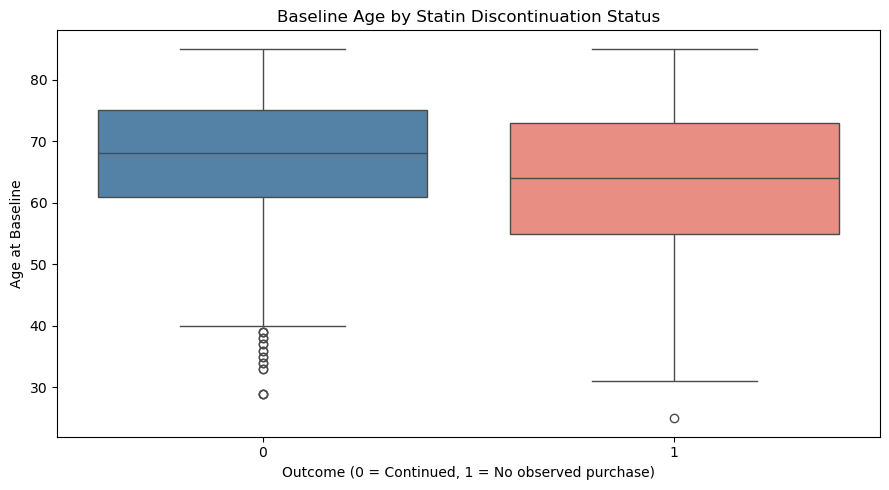

In [63]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=analysis_data,
    x="discontinued",
    y="AGE_round_1",
    hue="discontinued",
    palette=["steelblue", "salmon"],
    legend=False
)

plt.title("Baseline Age by Statin Discontinuation Status")
plt.xlabel("Outcome (0 = Continued, 1 = No observed purchase)")
plt.ylabel("Age at Baseline")
plt.tight_layout()
plt.show()

4.2.2 categorical demographic comparisons

In [65]:
def categorical_comparison(data, variable):

    summary = (
        data.groupby(
            ["discontinued", variable],
            dropna=False
        )
        .size()
        .reset_index(name="Count")
    )

    summary["Percentage"] = (
        summary.groupby("discontinued")["Count"]
        .transform(lambda x: x / x.sum() * 100)
    ).round(2)

    summary["Outcome"] = summary["discontinued"].map({
        0: "Continued",
        1: "No observed purchase"
    })

    return summary

demographic_vars = [
    "SEX_round_1",
    "RACETHX_round_1",
    "HISPANX_round_1",
    "HIDEG_round_1"
]

for col in demographic_vars:

    print(f"\n========== {col} ==========")

    display(
        categorical_comparison(analysis_data, col)
    )


========== SEX_round_1 ==========


,discontinued,SEX_round_1,Count,Percentage,Outcome
0,0,1,601,48.78,Continued
1,0,2,631,51.22,Continued
2,1,1,56,52.34,No observed purchase
3,1,2,51,47.66,No observed purchase



========== RACETHX_round_1 ==========


,discontinued,RACETHX_round_1,Count,Percentage,Outcome
0,0,1,171,13.88,Continued
1,0,2,844,68.51,Continued
2,0,3,146,11.85,Continued
3,0,4,44,3.57,Continued
4,0,5,27,2.19,Continued
5,1,1,22,20.56,No observed purchase
6,1,2,52,48.60,No observed purchase
7,1,3,24,22.43,No observed purchase
8,1,4,6,5.61,No observed purchase
9,1,5,3,2.80,No observed purchase



========== HISPANX_round_1 ==========


,discontinued,HISPANX_round_1,Count,Percentage,Outcome
0,0,1,171,13.88,Continued
1,0,2,1061,86.12,Continued
2,1,1,22,20.56,No observed purchase
3,1,2,85,79.44,No observed purchase



========== HIDEG_round_1 ==========


,discontinued,HIDEG_round_1,Count,Percentage,Outcome
0,0,-8,5,0.41,Continued
1,0,-7,1,0.08,Continued
2,0,1,161,13.07,Continued
3,0,2,71,5.76,Continued
4,0,3,479,38.88,Continued
5,0,4,224,18.18,Continued
6,0,5,134,10.88,Continued
7,0,6,34,2.76,Continued
8,0,7,123,9.98,Continued
9,1,-8,1,0.93,No observed purchase


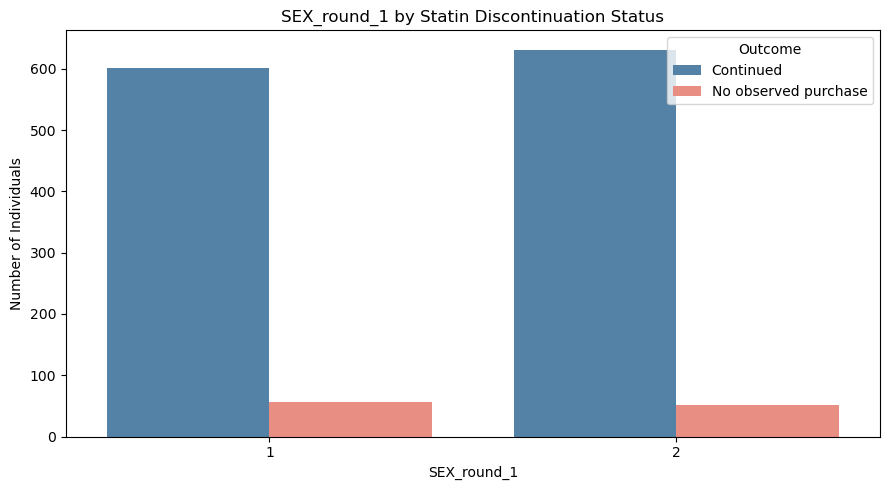

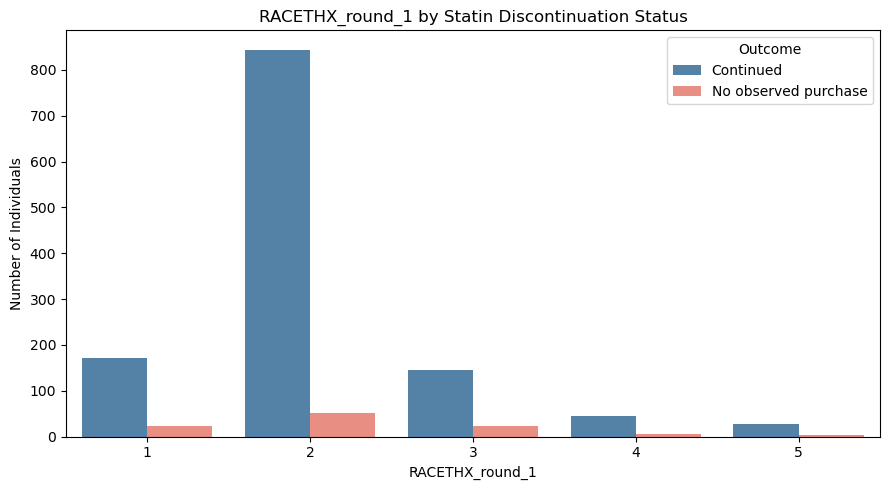

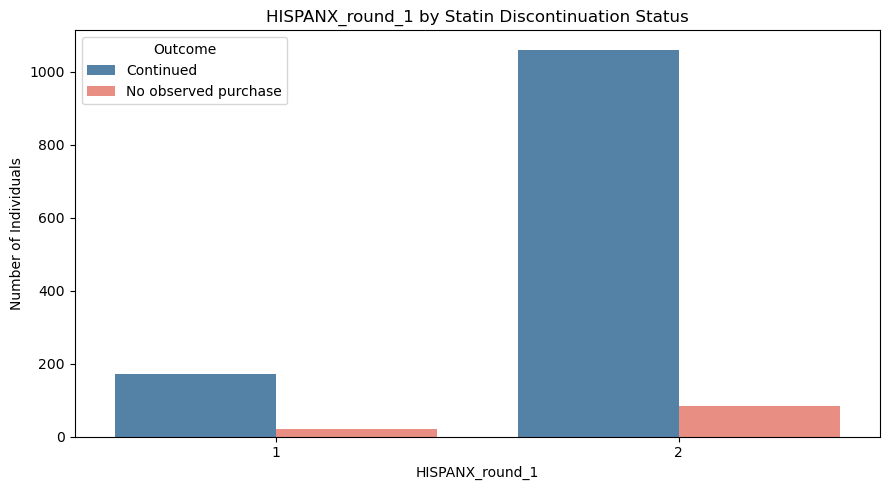

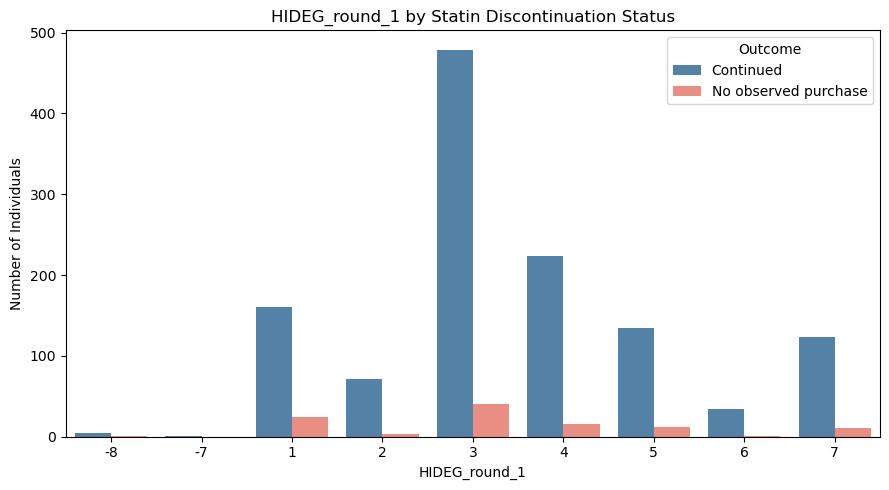

In [66]:
for col in demographic_vars:

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=analysis_data,
        x=col,
        hue="discontinued",
        palette=["steelblue", "salmon"]
    )

    plt.title(f"{col} by Statin Discontinuation Status")
    plt.xlabel(col)
    plt.ylabel("Number of Individuals")

    plt.legend(
        title="Outcome",
        labels=["Continued", "No observed purchase"]
    )

    plt.tight_layout()
    plt.show()

4.3 Health Characteristics by outcome

4.3.1 numerical health comparisons

In [69]:
health_numeric_vars = [
    "active_condition_count_round_1",
    "active_condition_count_round_2",
    "new_condition_count_round_1",
    "new_condition_count_round_2"
]

health_summary = (
    analysis_data.groupby("discontinued")[health_numeric_vars]
    .agg(["mean", "median", "std", "min", "max"])
    .round(2)
)

display(health_summary)

active_condition_count_round_1                       \
                                       mean median   std min max   
discontinued                                                       
0                                      3.92    3.0  3.08   0  25   
1                                      3.49    2.0  3.52   0  20   

             active_condition_count_round_2                       \
                                       mean median   std min max   
discontinued                                                       
0                                      4.94    4.0  3.35   0  27   
1                                      4.02    3.0  3.74   0  20   

             new_condition_count_round_1                       \
                                    mean median   std min max   
discontinued                                                    
0                                   3.92    3.0  3.08   0  25   
1                                   3.49    2.0  3.52   0  20   

             new_condition_count_round_2                       
                                    mean median   std min max  
discontinued                                                   
0                                   1.70    1.0  1.99   0  19  
1                                   1.57    1.0  2.12   0  12

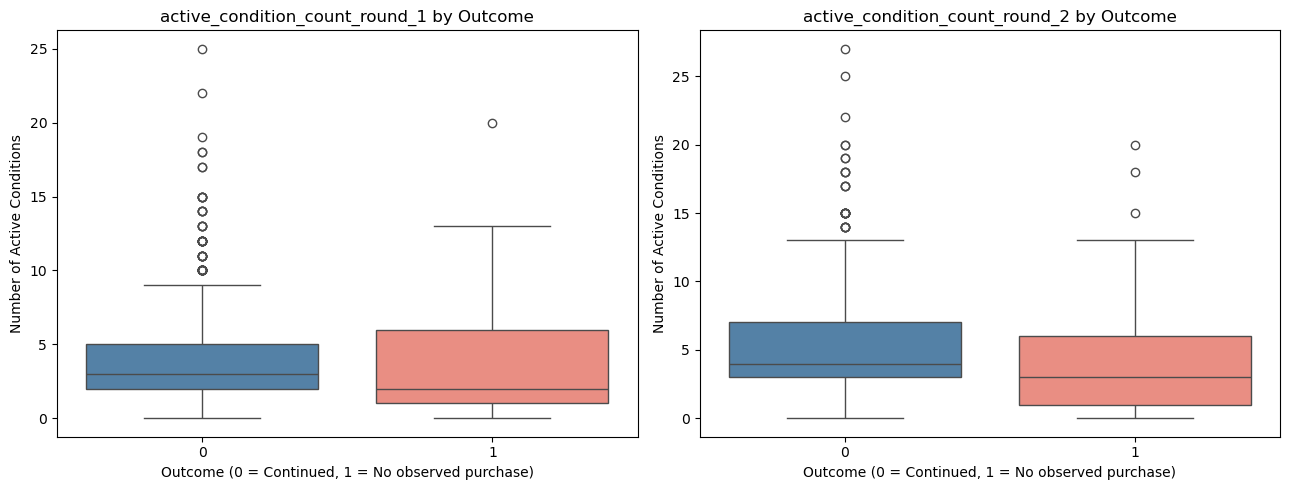

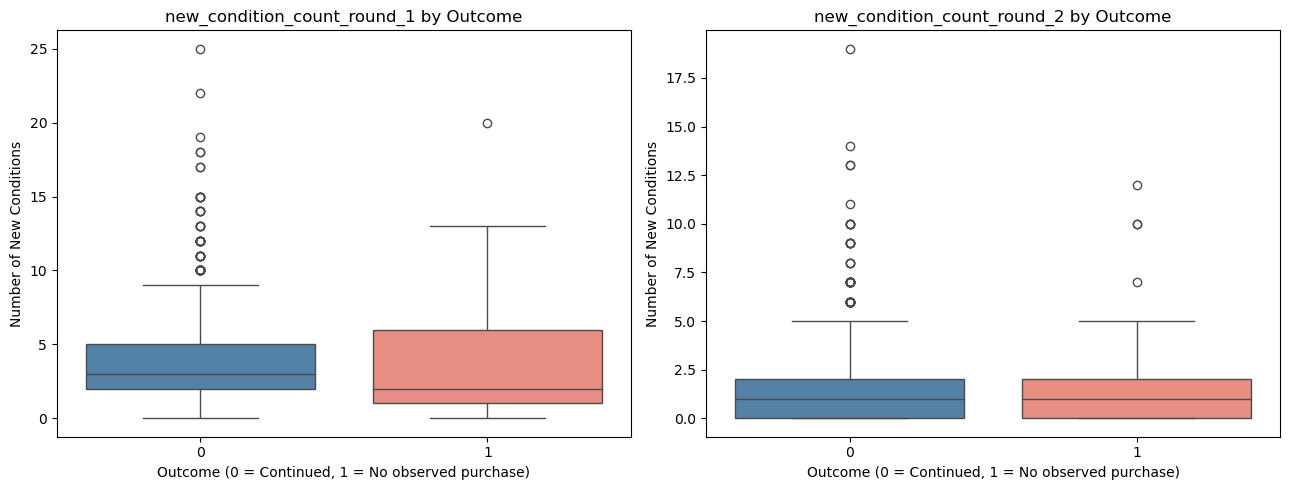

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, col in zip(
    axes,
    [
        "active_condition_count_round_1",
        "active_condition_count_round_2"
    ]
):

    sns.boxplot(
        data=analysis_data,
        x="discontinued",
        y=col,
        hue="discontinued",
        palette=["steelblue", "salmon"],
        legend=False,
        ax=ax
    )

    ax.set_title(f"{col} by Outcome")
    ax.set_xlabel("Outcome (0 = Continued, 1 = No observed purchase)")
    ax.set_ylabel("Number of Active Conditions")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, col in zip(
    axes,
    [
        "new_condition_count_round_1",
        "new_condition_count_round_2"
    ]
):

    sns.boxplot(
        data=analysis_data,
        x="discontinued",
        y=col,
        hue="discontinued",
        palette=["steelblue", "salmon"],
        legend=False,
        ax=ax
    )

    ax.set_title(f"{col} by Outcome")
    ax.set_xlabel("Outcome (0 = Continued, 1 = No observed purchase)")
    ax.set_ylabel("Number of New Conditions")

plt.tight_layout()
plt.show()

4.3.2 self reported health comparisons

In [72]:
health_categorical_vars = [
    "RTHLTH_round_1",
    "MNHLTH_round_1"
]

for col in health_categorical_vars:

    print(f"\n========== {col} ==========")

    display(
        categorical_comparison(analysis_data, col)
    )


========== RTHLTH_round_1 ==========


,discontinued,RTHLTH_round_1,Count,Percentage,Outcome
0,0,-7,1,0.08,Continued
1,0,1,148,12.01,Continued
2,0,2,403,32.71,Continued
3,0,3,390,31.66,Continued
4,0,4,210,17.05,Continued
5,0,5,80,6.49,Continued
6,1,1,13,12.15,No observed purchase
7,1,2,29,27.10,No observed purchase
8,1,3,37,34.58,No observed purchase
9,1,4,18,16.82,No observed purchase



========== MNHLTH_round_1 ==========


,discontinued,MNHLTH_round_1,Count,Percentage,Outcome
0,0,-7,1,0.08,Continued
1,0,1,330,26.79,Continued
2,0,2,389,31.57,Continued
3,0,3,362,29.38,Continued
4,0,4,129,10.47,Continued
5,0,5,21,1.70,Continued
6,1,1,18,16.82,No observed purchase
7,1,2,25,23.36,No observed purchase
8,1,3,47,43.93,No observed purchase
9,1,4,14,13.08,No observed purchase


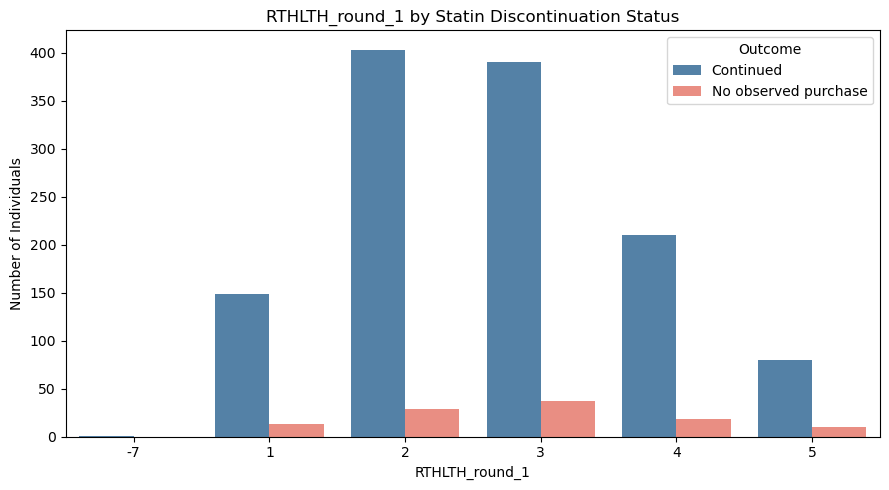

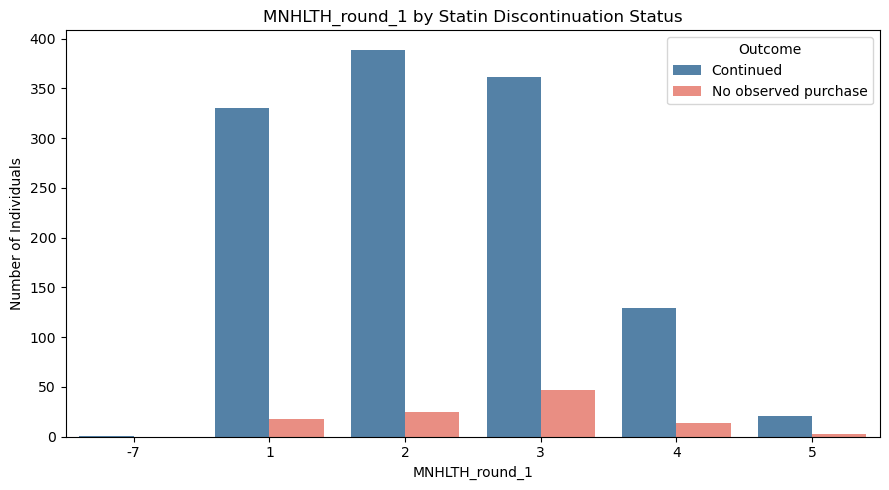

In [73]:
for col in health_categorical_vars:

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=analysis_data,
        x=col,
        hue="discontinued",
        palette=["steelblue", "salmon"]
    )

    plt.title(f"{col} by Statin Discontinuation Status")
    plt.xlabel(col)
    plt.ylabel("Number of Individuals")

    plt.legend(
        title="Outcome",
        labels=["Continued", "No observed purchase"]
    )

    plt.tight_layout()
    plt.show()

4.4 Insurance and access to care comparisons

4.4.1: categorical comparisons

In [76]:
insurance_vars = [
    "INS_round_1",
    "MCARE_round_1",
    "MCAID_round_1",
    "PRIVAT_round_1",
    "PMEDIN_round_1",
    "INSCOP_round_1",
    "ELGRND_round_1"
]

for col in insurance_vars:

    print(f"\n========== {col} ==========")

    display(
        categorical_comparison(analysis_data, col)
    )


========== INS_round_1 ==========


,discontinued,INS_round_1,Count,Percentage,Outcome
0,0,1,1198,97.24,Continued
1,0,2,34,2.76,Continued
2,1,1,94,87.85,No observed purchase
3,1,2,13,12.15,No observed purchase



========== MCARE_round_1 ==========


,discontinued,MCARE_round_1,Count,Percentage,Outcome
0,0,1,802,65.10,Continued
1,0,2,430,34.90,Continued
2,1,1,50,46.73,No observed purchase
3,1,2,57,53.27,No observed purchase



========== MCAID_round_1 ==========


,discontinued,MCAID_round_1,Count,Percentage,Outcome
0,0,1,155,12.58,Continued
1,0,2,1077,87.42,Continued
2,1,1,19,17.76,No observed purchase
3,1,2,88,82.24,No observed purchase


... (4 outputs left out)


========== INSCOP_round_1 ==========


,discontinued,INSCOP_round_1,Count,Percentage,Outcome
0,0,1,1232,100.0,Continued
1,1,1,107,100.0,No observed purchase



========== ELGRND_round_1 ==========


,discontinued,ELGRND_round_1,Count,Percentage,Outcome
0,0,1,1232,100.0,Continued
1,1,1,107,100.0,No observed purchase


4.4.2: visual comparisons

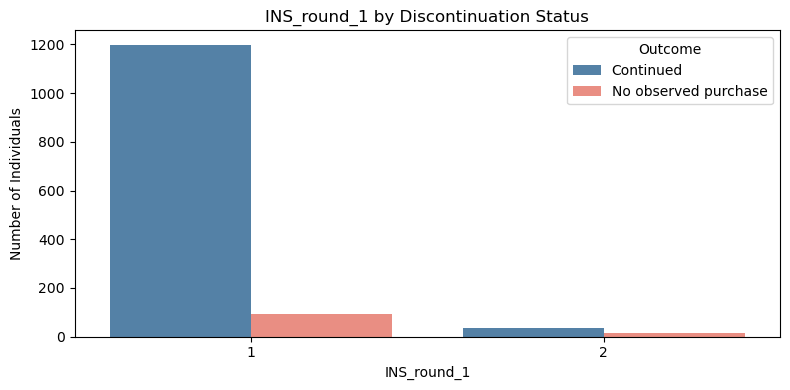

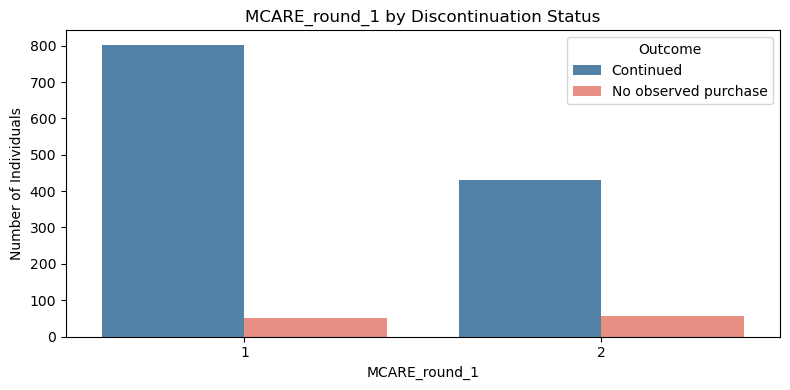

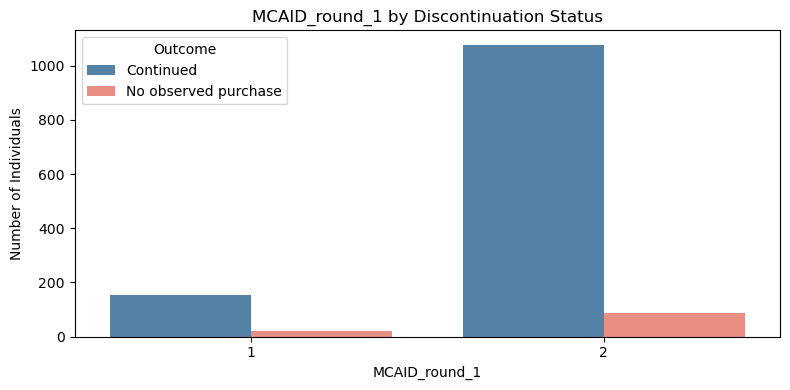

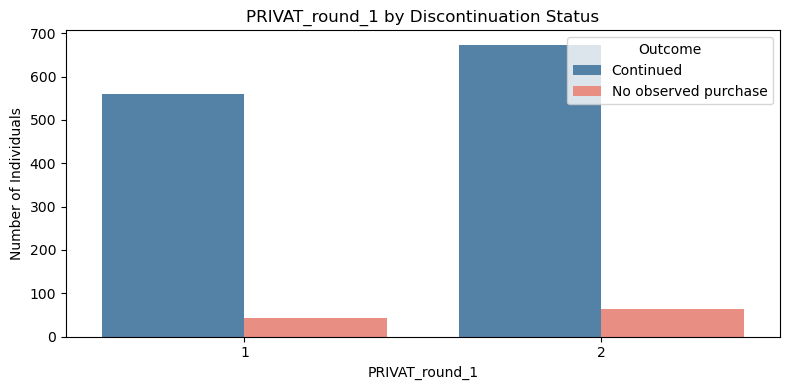

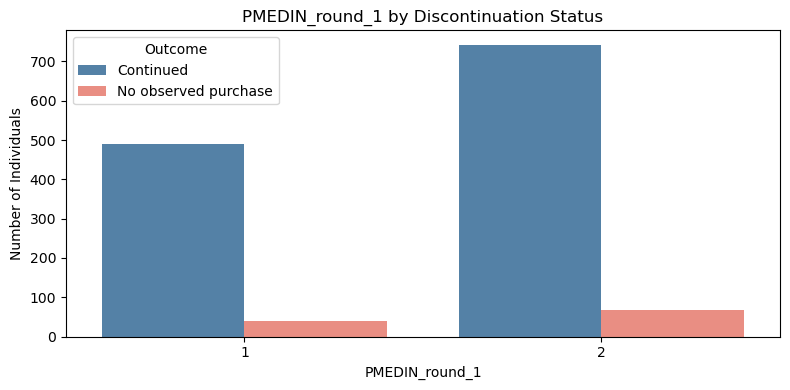

Skipping INSCOP_round_1: no variation
Skipping ELGRND_round_1: no variation


In [78]:
for col in insurance_vars:

    if analysis_data[col].nunique() <= 1:
        print(f"Skipping {col}: no variation")
        continue

    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=analysis_data,
        x=col,
        hue="discontinued",
        palette=["steelblue", "salmon"]
    )

    plt.title(f"{col} by Discontinuation Status")
    plt.xlabel(col)
    plt.ylabel("Number of Individuals")

    plt.legend(
        title="Outcome",
        labels=["Continued", "No observed purchase"]
    )

    plt.tight_layout()
    plt.show()

4.4.3 insurance coverage overview

In [80]:
insurance_overview = []

for col in insurance_vars:

    if analysis_data[col].nunique() <= 1:
        continue

    for outcome in [0, 1]:

        subset = analysis_data[
            analysis_data["discontinued"] == outcome
        ]

        insurance_overview.append({
            "Variable": col,
            "Outcome": (
                "Continued" if outcome == 0
                else "No observed purchase"
            ),
            "Individuals": len(subset),
            "Category_1_Count": (subset[col] == 1).sum(),
            "Category_1_Percentage": (
                (subset[col] == 1).mean() * 100
            ).round(2)
        })

insurance_overview = pd.DataFrame(insurance_overview)

display(insurance_overview)

,Variable,Outcome,Individuals,Category_1_Count,Category_1_Percentage
0,INS_round_1,Continued,1232,1198,97.24
1,INS_round_1,No observed purchase,107,94,87.85
2,MCARE_round_1,Continued,1232,802,65.10
3,MCARE_round_1,No observed purchase,107,50,46.73
4,MCAID_round_1,Continued,1232,155,12.58
5,MCAID_round_1,No observed purchase,107,19,17.76
6,PRIVAT_round_1,Continued,1232,559,45.37
7,PRIVAT_round_1,No observed purchase,107,44,41.12
8,PMEDIN_round_1,Continued,1232,490,39.77
9,PMEDIN_round_1,No observed purchase,107,39,36.45


4.5 baseline prescription purchasing patterns

In [82]:
baseline_prescription_summary = (
    baseline.groupby("discontinued")
    .agg(
        Individuals=("DUPERSID", "nunique"),
        Mean_Round_1_Purchases=(
            "rx_purchase_count_round_1", "mean"
        ),
        Mean_Round_2_Purchases=(
            "rx_purchase_count_round_2", "mean"
        ),
        Mean_Baseline_Purchases=(
            "rx_purchase_count_round_1",
            "mean"
        )
    )
    .round(2)
)

baseline["total_rx_purchases_baseline"] = (
    baseline["rx_purchase_count_round_1"] +
    baseline["rx_purchase_count_round_2"]
)

baseline_prescription_summary = (
    baseline.groupby("discontinued")
    .agg(
        Individuals=("DUPERSID", "nunique"),
        Mean_Round_1_Purchases=(
            "rx_purchase_count_round_1", "mean"
        ),
        Mean_Round_2_Purchases=(
            "rx_purchase_count_round_2", "mean"
        ),
        Mean_Baseline_Purchases=(
            "total_rx_purchases_baseline", "mean"
        ),
        Median_Baseline_Purchases=(
            "total_rx_purchases_baseline", "median"
        )
    )
    .round(2)
    .reset_index()
)

display(baseline_prescription_summary)

,discontinued,Individuals,Mean_Round_1_Purchases,Mean_Round_2_Purchases,Mean_Baseline_Purchases,Median_Baseline_Purchases
0,0,1232,7.60,12.13,19.73,14.0
1,1,107,7.82,11.27,19.09,9.0


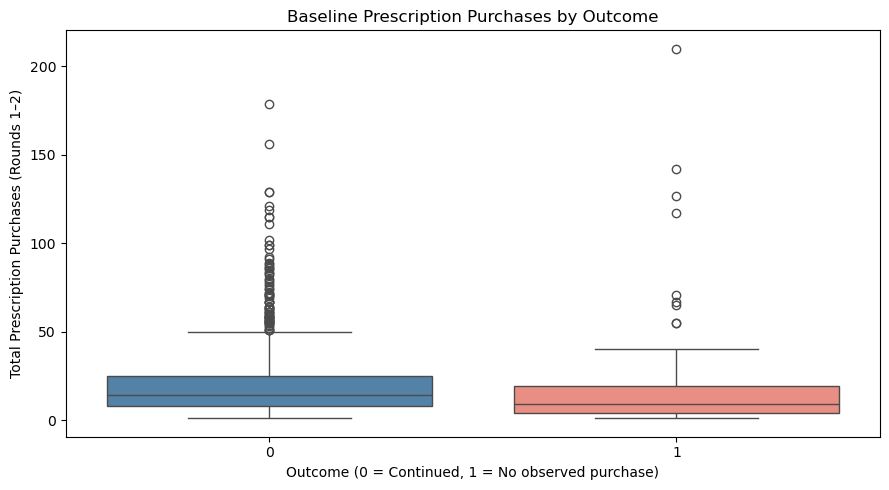

In [83]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=baseline,
    x="discontinued",
    y="total_rx_purchases_baseline",
    hue="discontinued",
    palette=["steelblue", "salmon"],
    legend=False
)

plt.title("Baseline Prescription Purchases by Outcome")
plt.xlabel("Outcome (0 = Continued, 1 = No observed purchase)")
plt.ylabel("Total Prescription Purchases (Rounds 1–2)")

plt.tight_layout()
plt.show()

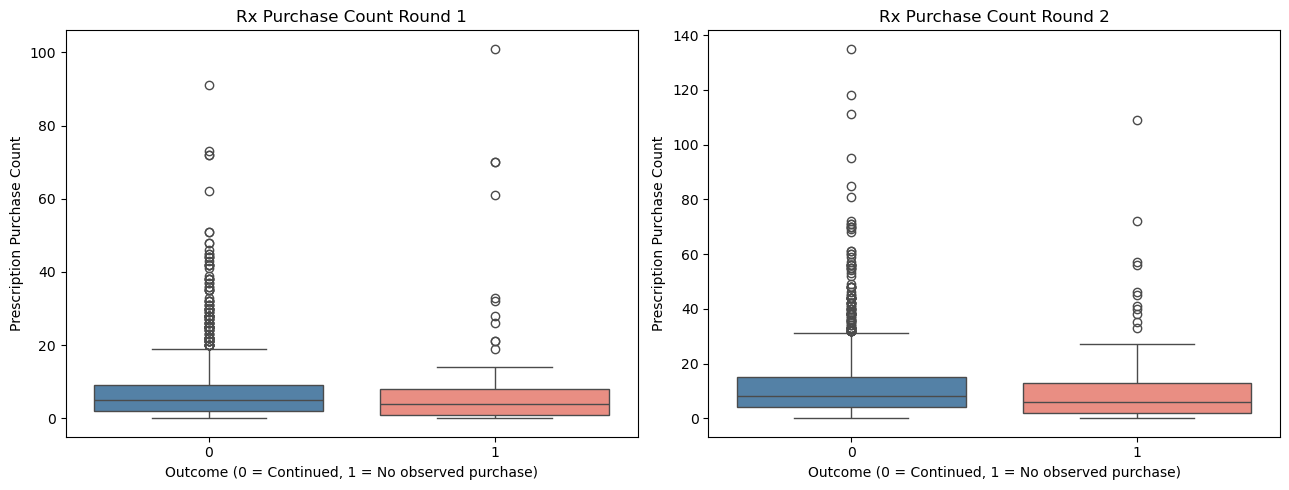

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, col in zip(
    axes,
    [
        "rx_purchase_count_round_1",
        "rx_purchase_count_round_2"
    ]
):

    sns.boxplot(
        data=baseline,
        x="discontinued",
        y=col,
        hue="discontinued",
        palette=["steelblue", "salmon"],
        legend=False,
        ax=ax
    )

    ax.set_title(f"{col.replace('_', ' ').title()}")
    ax.set_xlabel("Outcome (0 = Continued, 1 = No observed purchase)")
    ax.set_ylabel("Prescription Purchase Count")

plt.tight_layout()
plt.show()

4.6 Baseline statin purchasing patterns

In [86]:
baseline["total_statin_purchases_baseline"] = (
    baseline["statin_purchase_count_round_1"] +
    baseline["statin_purchase_count_round_2"]
)

statin_frequency_summary = (
    baseline.groupby("discontinued")
    .agg(
        Individuals=("DUPERSID", "nunique"),
        Mean_Round_1=(
            "statin_purchase_count_round_1", "mean"
        ),
        Mean_Round_2=(
            "statin_purchase_count_round_2", "mean"
        ),
        Mean_Baseline_Statin_Purchases=(
            "total_statin_purchases_baseline", "mean"
        ),
        Median_Baseline_Statin_Purchases=(
            "total_statin_purchases_baseline", "median"
        ),
        Zero_Baseline_Purchases=(
            "total_statin_purchases_baseline",
            lambda x: (x == 0).sum()
        )
    )
    .round(2)
    .reset_index()
)

display(statin_frequency_summary)

,discontinued,Individuals,Mean_Round_1,Mean_Round_2,Mean_Baseline_Statin_Purchases,Median_Baseline_Statin_Purchases,Zero_Baseline_Purchases
0,0,1232,1.21,1.87,3.08,3.0,0
1,1,107,1.16,1.61,2.77,2.0,0


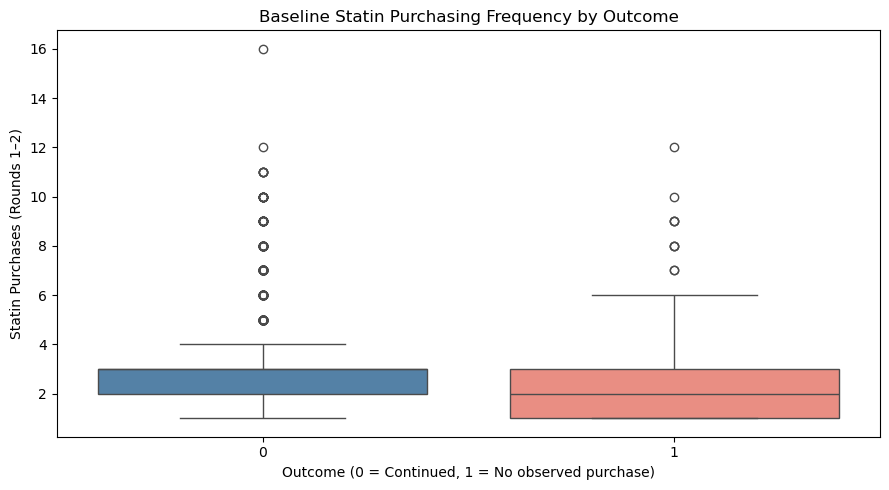

In [87]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=baseline,
    x="discontinued",
    y="total_statin_purchases_baseline",
    hue="discontinued",
    palette=["steelblue", "salmon"],
    legend=False
)

plt.title("Baseline Statin Purchasing Frequency by Outcome")
plt.xlabel("Outcome (0 = Continued, 1 = No observed purchase)")
plt.ylabel("Statin Purchases (Rounds 1–2)")

plt.tight_layout()
plt.show()

4.7 Statin switching and medication patterns

In [89]:
baseline_statins = baseline[
    [
        "DUPERSID",
        "discontinued",
        "standardized_statins_round_1",
        "standardized_statins_round_2"
    ]
].copy()

display(baseline_statins.head())

,DUPERSID,discontinued,standardized_statins_round_1,standardized_statins_round_2
0,2790006101,0,NaN,ATORVASTATIN
1,2790011101,0,PRAVASTATIN,PRAVASTATIN
2,2790011102,0,NaN,ATORVASTATIN
3,2790021101,0,NaN,SIMVASTATIN
4,2790049101,0,PRAVASTATIN,PRAVASTATIN


In [90]:
statin_records = []

for _, row in baseline_statins.iterrows():

    for round_col in [
        "standardized_statins_round_1",
        "standardized_statins_round_2"
    ]:

        value = row[round_col]

        if pd.notna(value):

            # Handle semicolon-separated statin names
            statins = [
                s.strip()
                for s in str(value).split(";")
                if s.strip()
            ]

            for statin in statins:
                statin_records.append({
                    "DUPERSID": row["DUPERSID"],
                    "discontinued": row["discontinued"],
                    "ROUND": round_col,
                    "Statin": statin
                })

baseline_statin_long = pd.DataFrame(statin_records)

display(baseline_statin_long.head())

,DUPERSID,discontinued,ROUND,Statin
0,2790006101,0,standardized_statins_round_2,ATORVASTATIN
1,2790011101,0,standardized_statins_round_1,PRAVASTATIN
2,2790011101,0,standardized_statins_round_2,PRAVASTATIN
3,2790011102,0,standardized_statins_round_2,ATORVASTATIN
4,2790021101,0,standardized_statins_round_2,SIMVASTATIN


In [91]:
statin_distribution = (
    baseline_statin_long["Statin"]
    .value_counts()
    .rename_axis("Statin")
    .reset_index(name="Records")
)

statin_distribution["Percentage"] = (
    statin_distribution["Records"] /
    statin_distribution["Records"].sum() * 100
).round(2)

display(statin_distribution)

,Statin,Records,Percentage
0,ATORVASTATIN,1192,56.84
1,ROSUVASTATIN,364,17.36
2,SIMVASTATIN,312,14.88
3,PRAVASTATIN,173,8.25
4,LOVASTATIN,56,2.67


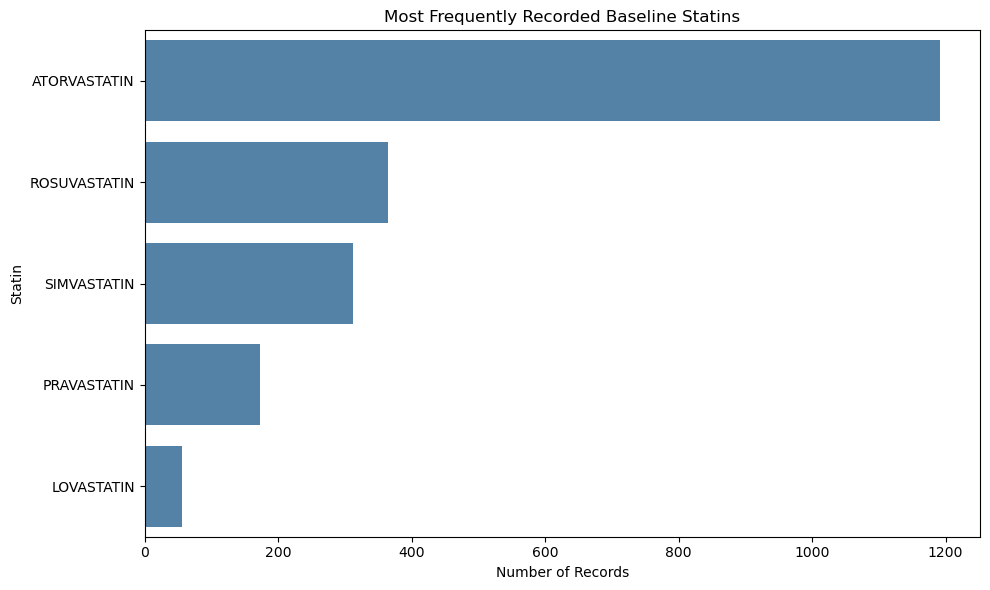

In [92]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=statin_distribution.head(10),
    x="Records",
    y="Statin",
    color="steelblue"
)

plt.title("Most Frequently Recorded Baseline Statins")
plt.xlabel("Number of Records")
plt.ylabel("Statin")

plt.tight_layout()
plt.show()

statin distribution by outcome

In [94]:
statin_outcome_summary = (
    baseline_statin_long
    .groupby(["discontinued", "Statin"])
    .size()
    .reset_index(name="Records")
)

statin_outcome_summary["Percentage"] = (
    statin_outcome_summary.groupby("discontinued")["Records"]
    .transform(lambda x: x / x.sum() * 100)
).round(2)

display(statin_outcome_summary)

,discontinued,Statin,Records,Percentage
0,0,ATORVASTATIN,1099,56.27
1,0,LOVASTATIN,53,2.71
2,0,PRAVASTATIN,166,8.50
3,0,ROSUVASTATIN,342,17.51
4,0,SIMVASTATIN,293,15.00
5,1,ATORVASTATIN,93,64.58
6,1,LOVASTATIN,3,2.08
7,1,PRAVASTATIN,7,4.86
8,1,ROSUVASTATIN,22,15.28
9,1,SIMVASTATIN,19,13.19


number of distinct statin types per individual

In [96]:
individual_statin_counts = (
    baseline_statin_long
    .groupby("DUPERSID")["Statin"]
    .nunique()
    .reset_index(name="distinct_baseline_statins")
)

individual_statin_counts = individual_statin_counts.merge(
    baseline[["DUPERSID", "discontinued"]],
    on="DUPERSID",
    how="left",
    validate="one_to_one"
)

statin_type_summary = (
    individual_statin_counts
    .groupby("discontinued")
    ["distinct_baseline_statins"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(statin_type_summary)

,count,mean,median,min,max
discontinued,,,,,
0,1229,1.02,1.0,1,2
1,107,1.01,1.0,1,2


Feature Comparisons and Purchase Patterns Summary

Research Question: How do patients with and without recorded discontinuation differ, and do early purchasing patterns provide useful signals?

Individuals with no observed statin purchases during follow-up differed from continuing purchasers in several baseline characteristics, particularly age, Medicare coverage, and early purchasing patterns. However, overall prescription and statin purchasing frequencies were relatively similar between groups. These descriptive comparisons identify potentially useful candidate predictors, but they do not establish whether the observed differences are statistically significant or independently associated with the outcome.

Key Findings:

Demographic characteristics: Individuals without observed follow-up purchases were younger on average than continuing purchasers (62.97 vs. 67.42 years). Sex distributions were relatively similar between groups, while differences were observed across race/ethnicity and education categories.

Health characteristics: Continuing purchasers had slightly higher average active condition counts in rounds 1 and 2 (3.92 vs. 3.49 and 4.94 vs. 4.02, respectively). Self-reported physical and mental health distributions also varied between outcome groups, although the differences were generally modest.

Insurance and healthcare access: Medicare coverage was less common in the no-observed-purchase group (46.73%) than among continuing purchasers (65.10%). Medicaid coverage was somewhat more common in the no-observed-purchase group (17.76% vs. 12.58%). Private insurance and prescription medication coverage showed relatively modest differences. The INSCOP_round_1 and ELGRND_round_1 variables had no variation and are unlikely to provide useful predictive information.

Baseline prescription purchasing patterns: Overall prescription purchasing frequency was similar between groups. Continuing purchasers averaged 19.73 prescription records across rounds 1–2, compared with 19.09 among individuals without observed follow-up purchases. However, median purchasing frequency was higher among continuing purchasers (14 vs. 9), suggesting differences in the distribution of early prescription utilization.

Baseline statin purchasing patterns: Continuing purchasers averaged 3.08 statin purchases during baseline, compared with 2.77 among individuals without observed follow-up purchases. Median counts were 3 and 2, respectively. These relatively small differences suggest that baseline statin purchasing frequency alone may have limited ability to distinguish between outcome groups.

Statin medication types: Atorvastatin was the most frequently recorded statin in both groups, representing 56.27% of statin records among continuing purchasers and 64.58% among individuals without observed follow-up purchases. The average number of distinct statin types per individual was nearly identical (1.02 vs. 1.01), indicating that most individuals had only one distinct statin type recorded during baseline.



5. Relationships Between Features
Research Question: Are features related, redundant, or potentially difficult to interpret together?

This section examines relationships among the available features to better understand how variables may interact or overlap. Correlations among appropriate numerical variables will be explored, with particular attention to relationships involving healthcare costs, income, insurance status, and prescription coverage.

Identifying highly related or redundant features is important for understanding the information represented within the dataset and recognizing potential multicollinearity concerns. These findings will help inform feature selection and improve the interpretability of subsequent modeling efforts.

5.1 numerical variables

In [100]:
# Create baseline dataset from round 1
baseline = history[
    history["ROUND"] == 1
].copy()

# Keep only individuals in the study cohort
baseline = baseline.merge(
    study_cohort[["DUPERSID", "discontinued"]],
    on="DUPERSID",
    how="inner",
    validate="one_to_one"
)

print("Baseline dimensions:", baseline.shape)
print("Unique individuals:", baseline["DUPERSID"].nunique())

display(baseline.head())

Baseline dimensions: (1339, 42)
Unique individuals: 1339


,DUPERSID,PANEL,ALL5RDS,DIED,INST,MILITARY,LEFTUS,SEX,RACETHX,HISPANX,...,statin_purchase_count,standardized_statins,generic_drug_names,reported_drug_names,statin_rx_cost,active_condition_count,new_condition_count,active_icd10_codes,active_ccsr_codes,discontinued
0,2790006101,27,1,0,0,0,0,2,2,2,...,0,NaN,LEVOTHYROXINE,EUTHYROX,0.00,2,2,C50; E03,END001; NEO030,0
1,2790011101,27,1,0,0,0,0,1,2,2,...,1,PRAVASTATIN,PRAVASTATIN,PRAVASTATIN,10.00,1,1,E78,END010,0
2,2790011102,27,1,0,0,0,0,2,2,2,...,0,NaN,GABAPENTIN; LOSARTAN,GABAPENTIN; LOSARTAN POT,0.00,3,3,I10; M79; S82,CIR007; INJ042; MUS025,0
3,2790021101,27,1,0,0,0,0,1,1,1,...,0,NaN,METFORMIN,METFORMIN,0.00,1,1,E11,END002; END005,0
4,2790049101,27,1,0,0,0,0,2,2,2,...,1,PRAVASTATIN,ASPIRIN; BRIMONIDINE OPHTHALMIC; CELECOXIB; LA...,ASPIRIN LOW; BRIMONIDINE; CELECOXIB; LATANOPRO...,14.61,3,3,E78; H40; Z96,END010; EYE003; FAC009,0


In [101]:
numeric_features = [
    "AGE",
    "LONGWT",
    "rx_purchase_count",
    "distinct_drug_count",
    "statin_purchase_count",
    "active_condition_count",
    "new_condition_count",
    "EDUCYR"
]

correlation_data = baseline[numeric_features].copy()

display(correlation_data.describe().round(2))

,AGE,LONGWT,rx_purchase_count,distinct_drug_count,statin_purchase_count,active_condition_count,new_condition_count,EDUCYR
count,1339.00,1339.00,1339.00,1339.00,1339.00,1339.00,1339.00,1339.00
mean,67.06,31439.26,7.62,4.44,1.20,3.89,3.89,12.99
std,11.09,23978.39,9.99,3.81,1.28,3.12,3.12,3.49
min,25.00,1797.33,0.00,0.00,0.00,0.00,0.00,-8.00
25%,60.50,17255.02,2.00,2.00,0.00,2.00,2.00,12.00
50%,68.00,26068.92,5.00,4.00,1.00,3.00,3.00,13.00
75%,75.00,38556.55,9.00,6.00,1.00,5.00,5.00,16.00
max,85.00,260973.88,101.00,24.00,7.00,25.00,25.00,17.00


5.2 preparing correlation data

In [103]:
# Make a copy for correlation analysis
correlation_data = baseline[numeric_features].copy()

# Treat negative education codes as missing
correlation_data.loc[
    correlation_data["EDUCYR"] < 0,
    "EDUCYR"
] = np.nan

# Check missing values
display(
    correlation_data.isna().sum().to_frame(
        name="Missing Values"
    )
)

,Missing Values
AGE,0
LONGWT,0
rx_purchase_count,0
distinct_drug_count,0
statin_purchase_count,0
active_condition_count,0
new_condition_count,0
EDUCYR,6


5.3 Pearson correlation

,AGE,LONGWT,rx_purchase_count,distinct_drug_count,statin_purchase_count,active_condition_count,new_condition_count,EDUCYR
AGE,1.000,-0.112,-0.068,0.032,-0.098,0.066,0.066,-0.049
LONGWT,-0.112,1.000,0.010,0.002,0.023,0.001,0.001,0.122
rx_purchase_count,-0.068,0.010,1.000,0.763,0.677,0.620,0.620,-0.074
distinct_drug_count,0.032,0.002,0.763,1.000,0.381,0.797,0.797,-0.036
statin_purchase_count,-0.098,0.023,0.677,0.381,1.000,0.330,0.330,-0.009
active_condition_count,0.066,0.001,0.620,0.797,0.330,1.000,1.000,0.043
new_condition_count,0.066,0.001,0.620,0.797,0.330,1.000,1.000,0.043
EDUCYR,-0.049,0.122,-0.074,-0.036,-0.009,0.043,0.043,1.000


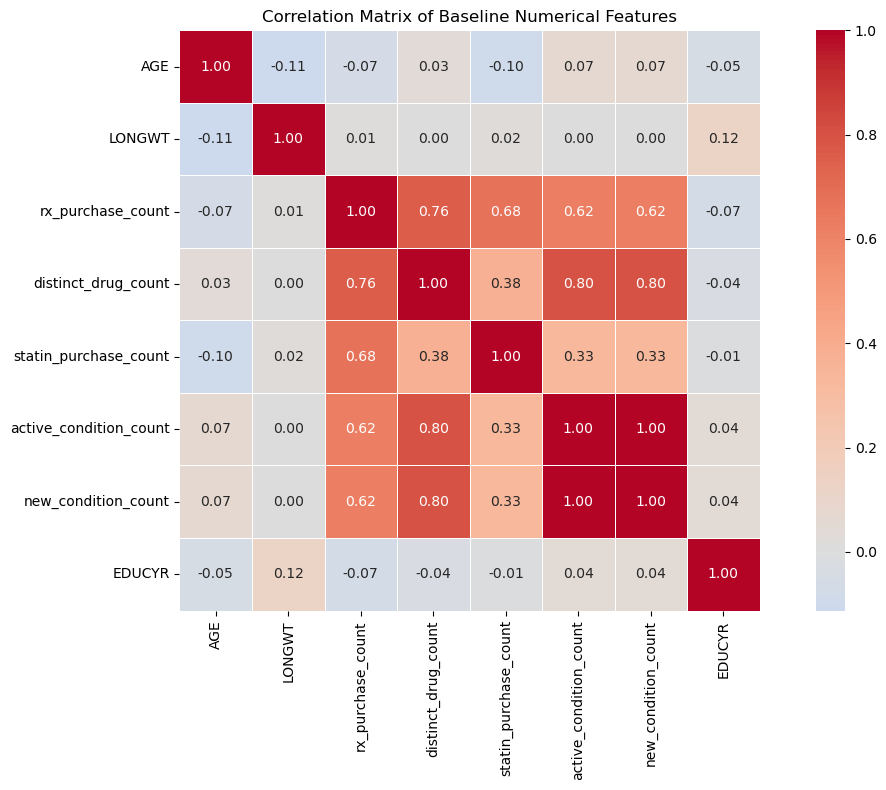

In [105]:
correlation_matrix = correlation_data.corr(
    method="pearson"
)

display(correlation_matrix.round(3))

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    square=True,
    linewidths=0.5
)

plt.title("Correlation Matrix of Baseline Numerical Features")
plt.tight_layout()
plt.show()

5.4 insurance and prescription coverage relationships

In [107]:
insurance_vars = [
    "INS",
    "MCARE",
    "MCAID",
    "PRIVAT",
    "PMEDIN"
]

for var in insurance_vars:
    print(f"\n========== {var} vs PMEDIN ==========")

    display(
        pd.crosstab(
            baseline[var],
            baseline["PMEDIN"],
            normalize="index"
        ).round(3) * 100
    )


========== INS vs PMEDIN ==========


PMEDIN,1,2
INS,,
1,40.9,59.1
2,2.1,97.9



========== MCARE vs PMEDIN ==========


PMEDIN,1,2
MCARE,,
1,24.8,75.2
2,65.3,34.7



========== MCAID vs PMEDIN ==========


PMEDIN,1,2
MCAID,,
1,5.2,94.8
2,44.6,55.4



========== PRIVAT vs PMEDIN ==========


PMEDIN,1,2
PRIVAT,,
1,85.7,14.3
2,1.6,98.4



========== PMEDIN vs PMEDIN ==========


PMEDIN,1,2
PMEDIN,,
1,100.0,0.0
2,0.0,100.0


In [108]:
insurance_corr = baseline[
    insurance_vars
].corr(method="spearman")

display(insurance_corr.round(3))

,INS,MCARE,MCAID,PRIVAT,PMEDIN
INS,1.000,0.252,0.074,0.164,0.146
MCARE,0.252,1.000,-0.091,-0.370,-0.399
MCAID,0.074,-0.091,1.000,-0.296,-0.271
PRIVAT,0.164,-0.370,-0.296,1.000,0.856
PMEDIN,0.146,-0.399,-0.271,0.856,1.000


5.5 costs, income, and insurance relationships

In [110]:
financial_features = [
    "statin_rx_cost",
    "rx_purchase_count",
    "distinct_drug_count",
    "statin_purchase_count"
]

financial_data = baseline[financial_features].copy()

display(financial_data.describe().round(2))

display(
    financial_data.corr(method="spearman").round(3)
)

,statin_rx_cost,rx_purchase_count,distinct_drug_count,statin_purchase_count
count,1339.00,1339.00,1339.00,1339.00
mean,7.50,7.62,4.44,1.20
std,46.31,9.99,3.81,1.28
min,0.00,0.00,0.00,0.00
25%,0.00,2.00,2.00,0.00
50%,0.00,5.00,4.00,1.00
75%,4.64,9.00,6.00,1.00
max,1524.80,101.00,24.00,7.00


,statin_rx_cost,rx_purchase_count,distinct_drug_count,statin_purchase_count
statin_rx_cost,1.000,0.250,0.224,0.398
rx_purchase_count,0.250,1.000,0.910,0.695
distinct_drug_count,0.224,0.910,1.000,0.547
statin_purchase_count,0.398,0.695,0.547,1.000


Relationships Between Features Summary

Research Question: Are features related, redundant, or potentially difficult to interpret together?

Several baseline features demonstrated meaningful relationships, and some contained overlapping or redundant information. The strongest relationships were observed among prescription utilization variables, insurance coverage indicators, and health condition measures. Active condition counts and new condition counts demonstrated a perfect correlation, indicating redundancy in the dataset. Private insurance and prescription medication coverage also demonstrated a strong positive association. 

Key Findings:

Numerical relationships: Total prescription purchases were strongly correlated with distinct medication counts (Pearson r = 0.763) and statin purchase counts (r = 0.677). Distinct medication counts were also strongly correlated with active condition counts (r = 0.797). These relationships indicate that several prescription utilization and health characteristics capture related aspects of patient healthcare utilization.

Health characteristics and feature redundancy: Active condition counts and new condition counts demonstrated a perfect positive correlation (r = 1.000). This indicates that the two variables contain identical information in the current baseline dataset. Including both variables in subsequent predictive models could introduce unnecessary redundancy.

Insurance and prescription coverage: Private insurance and prescription medication coverage demonstrated a strong positive association (Spearman r = 0.856). Medicare and Medicaid indicators showed negative associations with prescription medication coverage. Cross-tabulations also demonstrated differences in prescription coverage across insurance categories.

Income and out-of-pocket costs: Household income was not available in the current processed baseline dataset. Consequently, the relationship between income and statin out-of-pocket costs could not be evaluated. However, statin out-of-pocket costs demonstrated positive associations with statin purchase frequency (Spearman r = 0.398) and overall prescription purchasing frequency (r = 0.250).

Age and healthcare utilization: Age demonstrated relatively weak correlations with prescription purchasing frequency (r = -0.068), distinct medication counts (r = 0.032), and statin purchase frequency (r = -0.098). These findings suggest that age had limited linear associations with the available baseline prescription utilization measures.

Missing data and data quality: Six observations (0.45%) had missing education values after negative survey codes were treated as missing. All other selected numerical variables were complete.


6. Subgroup Representation and Equity
Research Question: Do we have sufficient data to evaluate model performance across patient groups?

This section evaluates the representation of different patient populations within the study cohort and identifies potential limitations for subgroup analysis. Cohort sizes, outcome prevalence, and missingness will be examined across relevant demographic and socioeconomic characteristics, including age, sex, race/ethnicity, insurance status, and income.

6.1 Preparing subgroups

In [114]:
# Create a working copy
subgroup_data = baseline.copy()

# Create age groups
subgroup_data["age_group"] = pd.cut(
    subgroup_data["AGE"],
    bins=[18, 44, 54, 64, 74, 100],
    labels=[
        "18-44",
        "45-54",
        "55-64",
        "65-74",
        "75+"
    ],
    include_lowest=True
)

# Outcome labels
subgroup_data["outcome"] = (
    subgroup_data["discontinued"]
    .map({
        0: "Continued",
        1: "No observed purchase"
    })
)

print("Subgroup dataset dimensions:", subgroup_data.shape)

display(
    subgroup_data[
        ["AGE", "age_group", "SEX", "RACETHX",
         "HISPANX", "INS", "MCARE", "MCAID",
         "PRIVAT", "PMEDIN", "discontinued"]
    ].head()
)

Subgroup dataset dimensions: (1339, 44)


,AGE,age_group,SEX,RACETHX,HISPANX,INS,MCARE,MCAID,PRIVAT,PMEDIN,discontinued
0,74,65-74,2,2,2,1,1,2,2,2,0
1,69,65-74,1,2,2,1,1,2,1,2,0
2,69,65-74,2,2,2,1,1,2,1,2,0
3,56,55-64,1,1,1,1,2,2,1,1,0
4,63,55-64,2,2,2,1,2,2,1,1,0


6.2 Subgroup size and outcome prevalance

In [116]:
def subgroup_summary(df, variable):

    summary = (
        df.groupby(variable, observed=False)
        .agg(
            Individuals=("DUPERSID", "nunique"),
            Discontinued=("discontinued", "sum"),
            Missing=("discontinued", "count")
        )
        .reset_index()
    )

    summary["Continued"] = (
        summary["Individuals"] -
        summary["Discontinued"]
    )

    summary["Discontinuation (%)"] = (
        summary["Discontinued"] /
        summary["Individuals"] * 100
    ).round(2)

    summary["Cohort (%)"] = (
        summary["Individuals"] /
        len(df) * 100
    ).round(2)

    return summary

subgroup_variables = [
    "age_group",
    "SEX",
    "RACETHX",
    "HISPANX"
]

for variable in subgroup_variables:

    print(f"\n========== {variable} ==========")

    display(
        subgroup_summary(
            subgroup_data,
            variable
        )
    )


========== age_group ==========


,age_group,Individuals,Discontinued,Missing,Continued,Discontinuation (%),Cohort (%)
0,18-44,50,11,50,39,22.00,3.73
1,45-54,124,14,124,110,11.29,9.26
2,55-64,331,31,331,300,9.37,24.72
3,65-74,470,31,470,439,6.60,35.10
4,75+,364,20,364,344,5.49,27.18



========== SEX ==========


,SEX,Individuals,Discontinued,Missing,Continued,Discontinuation (%),Cohort (%)
0,1,657,56,657,601,8.52,49.07
1,2,682,51,682,631,7.48,50.93



========== RACETHX ==========


,RACETHX,Individuals,Discontinued,Missing,Continued,Discontinuation (%),Cohort (%)
0,1,193,22,193,171,11.40,14.41
1,2,896,52,896,844,5.80,66.92
2,3,170,24,170,146,14.12,12.70
3,4,50,6,50,44,12.00,3.73
4,5,30,3,30,27,10.00,2.24



========== HISPANX ==========


,HISPANX,Individuals,Discontinued,Missing,Continued,Discontinuation (%),Cohort (%)
0,1,193,22,193,171,11.40,14.41
1,2,1146,85,1146,1061,7.42,85.59


6.3 Insurance subgroup representation

In [118]:
insurance_variables = [
    "INS",
    "MCARE",
    "MCAID",
    "PRIVAT",
    "PMEDIN"
]

for variable in insurance_variables:

    print(f"\n========== {variable} ==========")

    display(
        subgroup_summary(
            subgroup_data,
            variable
        )
    )


========== INS ==========


,INS,Individuals,Discontinued,Missing,Continued,Discontinuation (%),Cohort (%)
0,1,1292,94,1292,1198,7.28,96.49
1,2,47,13,47,34,27.66,3.51



========== MCARE ==========


,MCARE,Individuals,Discontinued,Missing,Continued,Discontinuation (%),Cohort (%)
0,1,852,50,852,802,5.87,63.63
1,2,487,57,487,430,11.70,36.37



========== MCAID ==========


,MCAID,Individuals,Discontinued,Missing,Continued,Discontinuation (%),Cohort (%)
0,1,174,19,174,155,10.92,12.99
1,2,1165,88,1165,1077,7.55,87.01



========== PRIVAT ==========


,PRIVAT,Individuals,Discontinued,Missing,Continued,Discontinuation (%),Cohort (%)
0,1,603,44,603,559,7.30,45.03
1,2,736,63,736,673,8.56,54.97



========== PMEDIN ==========


,PMEDIN,Individuals,Discontinued,Missing,Continued,Discontinuation (%),Cohort (%)
0,1,529,39,529,490,7.37,39.51
1,2,810,68,810,742,8.40,60.49


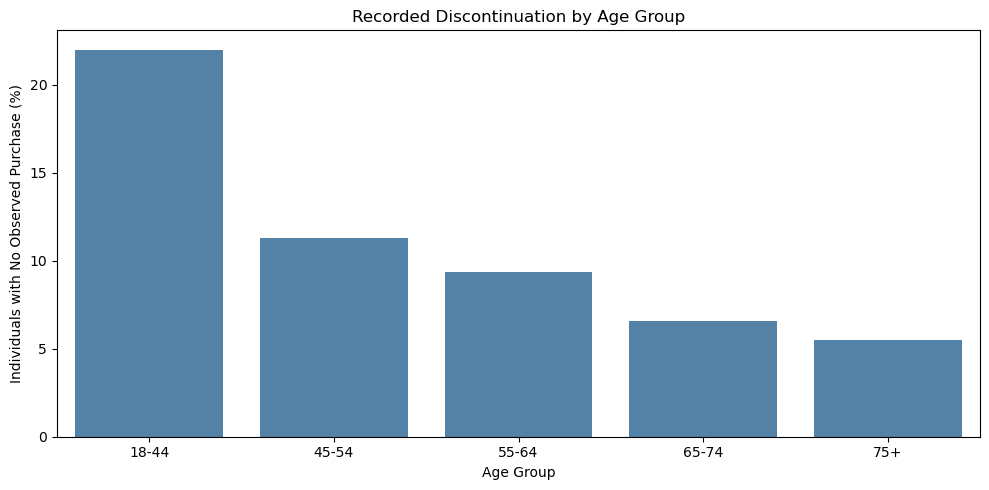

In [119]:
age_summary = subgroup_summary(
    subgroup_data,
    "age_group"
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=age_summary,
    x="age_group",
    y="Discontinuation (%)",
    color="steelblue"
)

plt.title("Recorded Discontinuation by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Individuals with No Observed Purchase (%)")

plt.tight_layout()
plt.show()

6.4: identify small subgroups

In [121]:
small_subgroups = []

for variable in subgroup_variables + insurance_variables:

    summary = subgroup_summary(
        subgroup_data,
        variable
    )

    summary["Variable"] = variable
    summary["Category"] = summary[variable].astype(str)

    small_subgroups.append(
        summary[
            [
                "Variable",
                "Category",
                "Individuals",
                "Discontinued",
                "Discontinuation (%)"
            ]
        ]
    )

small_subgroups_df = pd.concat(
    small_subgroups,
    ignore_index=True
)

display(
    small_subgroups_df.sort_values(
        "Individuals"
    )
)

,Variable,Category,Individuals,Discontinued,Discontinuation (%)
11,RACETHX,5,30,3,10.00
15,INS,2,47,13,27.66
10,RACETHX,4,50,6,12.00
0,age_group,18-44,50,11,22.00
1,age_group,45-54,124,14,11.29
9,RACETHX,3,170,24,14.12
18,MCAID,1,174,19,10.92
7,RACETHX,1,193,22,11.40
12,HISPANX,1,193,22,11.40
2,age_group,55-64,331,31,9.37


6.5 Missingness by subgroup

In [123]:
equity_variables = [
    "AGE",
    "SEX",
    "RACETHX",
    "HISPANX",
    "EDUCYR",
    "INS",
    "MCARE",
    "MCAID",
    "PRIVAT",
    "PMEDIN"
]

equity_missingness = pd.DataFrame({
    "Variable": equity_variables,
    "Missing Count": [
        subgroup_data[col].isna().sum()
        for col in equity_variables
    ],
    "Missing Percentage": [
        subgroup_data[col].isna().mean() * 100
        for col in equity_variables
    ]
})

equity_missingness["Missing Percentage"] = (
    equity_missingness["Missing Percentage"].round(2)
)

display(equity_missingness)

,Variable,Missing Count,Missing Percentage
0,AGE,0,0.0
1,SEX,0,0.0
2,RACETHX,0,0.0
3,HISPANX,0,0.0
4,EDUCYR,0,0.0
5,INS,0,0.0
6,MCARE,0,0.0
7,MCAID,0,0.0
8,PRIVAT,0,0.0
9,PMEDIN,0,0.0


Subgroup Representation and Equity Summary

Research Question: Do we have sufficient data to evaluate model performance across patient groups?

The study cohort provides sufficient data for preliminary evaluation of model performance across some patient groups, particularly sex and larger age and insurance categories. However, the cohort does not provide sufficient representation to support reliable performance comparisons across all demographic and insurance subgroups. Although the cohort includes 1,339 individuals, several smaller subgroups have limited sample sizes and few recorded potential discontinuation events, restricting the precision and reliability of subgroup-specific performance estimates.

Key Findings:

Age-group representation: Recorded discontinuation prevalence was highest among individuals aged 18–44 (22.00%) and lowest among those aged 75 and older (5.49%). The youngest age group contained only 50 individuals and 11 outcome events, limiting the precision of subgroup performance estimates.

Sex representation: The cohort was relatively balanced across the two recorded sex categories (49.07% and 50.93%). Discontinuation prevalence was also similar between groups (8.52% and 7.48%), with 56 and 51 outcome events, respectively. This provides a comparatively strong basis for evaluating model performance across these groups.

Race and ethnicity representation: The cohort was concentrated in one race category, representing 66.92% of participants. Discontinuation prevalence varied across race categories, ranging from 5.80% to 14.12%. The smallest race category contained only 30 individuals and three outcome events, limiting the reliability of subgroup-specific performance estimates. Hispanic ethnicity was similarly concentrated, with 85.59% of participants belonging to one category.

Insurance representation: Insurance categories demonstrated differences in recorded discontinuation prevalence. General insurance category 2 had a prevalence of 27.66%, compared with 7.28% in category 1, although the smaller category contained only 47 individuals and 13 outcome events. Medicare categories also differed (11.70% vs. 5.87%), while Medicaid, private insurance, and prescription medication coverage showed smaller differences.

Small subgroup representation: Several subgroups had limited representation, particularly smaller race categories, general insurance category 2, and younger age groups. The relatively small number of outcome events in these groups may produce unstable estimates of sensitivity, specificity, and other predictive performance metrics. 

Missingness and data quality: The demographic and insurance variables examined contained no missing observations. However, six education observations (0.45%) contained negative survey codes.


7. EDA Summary and Modeling Decisions
Research Question: What did we learn, and how should it inform our modeling approach?

This final section synthesizes the findings from the exploratory data analysis and translates them into decisions for subsequent modeling stages. Key findings will include the final cohort size, outcome prevalence, data quality concerns, and any preprocessing decisions established during the analysis.

Potential predictors will be identified based on their distributions, relationships with the outcome, and relevance to the research question. Missing-data strategies, feature selection considerations, potential data leakage risks, and limitations related to subgroup representation will also be documented.

EDA and Modeling Decisions Summary

Research Question: What did we learn, and how should it inform our modeling approach?

The exploratory data analysis established a study cohort of 1,339 adults with baseline statin purchasing activity and identified several demographic, healthcare, financial, and prescription-related characteristics that may be relevant to predicting the absence of observed statin purchases during follow-up. The data is suitable for proceeding to feature engineering and model development, provided that important limitations are addressed. These include substantial outcome imbalance, incomplete medication classification, redundant features, special survey codes, and limited representation within certain patient subgroups. The findings also show that the outcome represents observed purchasing behavior rather than confirmed medication discontinuation.

Key Findings and Modeling Considerations:

Study population and outcome: The final cohort contains 1,339 individuals, with 107 (7.99%) classified as having no observed statin purchases during rounds 3–5. The resulting class imbalance should be considered when selecting modeling strategies, evaluation metrics, and classification thresholds.

Candidate predictors: Age, Medicare coverage, baseline healthcare characteristics, prescription utilization, statin purchasing frequency, and out-of-pocket costs demonstrated potentially meaningful differences or relationships. These variables should be considered during feature engineering and subsequent predictive evaluation.

Feature redundancy: Active condition counts and new condition counts demonstrated a perfect correlation (r = 1.000), suggesting that they contain identical information in the current dataset. Prescription utilization and insurance-related variables also demonstrated substantial associations. These features should be reviewed to identify unnecessary redundancy.

Missing data and preprocessing: Although the selected baseline feature set was largely complete, six education observations contained negative survey codes that should be treated as missing. Standardized statin medication information also contained missing values and will require an appropriate strategy if included in modeling.

Variable distributions: Financial variables exhibited substantial right skewness, and nearly half of the cohort had zero recorded baseline statin out-of-pocket costs. These characteristics should be considered when evaluating transformations, scaling, and the treatment of zero-cost observations.

Potential data leakage: Predictor selection must be restricted to information available during the baseline period (rounds 1–2). Variables derived from follow-up purchasing behavior in rounds 3–5 must not be included as predictors because they directly contribute to defining the outcome.

Subgroup representation: Sex and larger age and insurance categories provide a stronger basis for subgroup evaluation than smaller race, age, and insurance categories. Subgroup sample sizes and outcome event counts should be considered when interpreting model performance.

Outcome interpretation: The absence of recorded statin purchases during follow-up does not necessarily confirm that an individual stopped taking statins. The outcome should consistently be described as no observed follow-up purchases or potential discontinuation throughout the modeling and reporting process.
